# Предобработка и графики

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def open_saved_table(csv_file):
    if os.path.exists(csv_file):
        return pd.read_csv(csv_file, encoding="utf-8-sig")
    else:
        raise FileNotFoundError(f"Нет файла: {csv_file}")

df = open_saved_table("data/final/channels_final.csv")

In [2]:
# Обработка числовых столбцов

if {'er_general', 'er_daily'}.issubset(df.columns):
  df["er_general_percent"] = df["er_general"].apply(lambda s: float(str(s).rstrip("%")) if pd.notna(s) else None)
  df["er_daily_percent"] = df["er_daily"].apply(lambda s: float(str(s).rstrip("%")) if pd.notna(s) else None)
  df = df.drop(columns = ["er_general", "er_daily"])

df["subscribers"] = df["subscribers"].astype("Int64")
df["subs_delta_day"] = df["subs_delta_day"].astype("Int64")
df["views_per_post"] = df["views_per_post"].astype("Int64")

def parse_number(s):
    if pd.isna(s):
        return None
    s = str(s).strip().upper()
    try:
        if s.endswith("K"):
            return int(float(s[:-1]) * 1_000)
        elif s.endswith("M"):
            return int(float(s[:-1]) * 1_000_000)
        else:
            return int(float(s))
    except ValueError:
        return None

df["num_likes"] = df["num_likes"].apply(parse_number).astype("Int64")
df["num_posts"] = df["num_posts"].apply(parse_number).astype("Int64")
df["num_messages"] = df["num_messages"].apply(parse_number).astype("Int64")
df["num_replies"] = df["num_replies"].apply(parse_number).astype("Int64")
df["num_quotes"] = df["num_quotes"].apply(parse_number).astype("Int64")
df["posts_showing"] = df["posts_showing"].astype("Int64")


# Добавление числовых столбцов
df["er_calculated"] = df["views_per_post"] / df["subscribers"] * 100
df["views"] = df["views_per_post"] * df["num_posts"]
df["reactions"] = df["num_messages"] + df["num_quotes"] + df["num_likes"] # как видно ниже, replies является подмножеством quotes, поэтому не включается дважды
df["reactions_per_view"] = (df["reactions"] / df["views"].replace(0, np.nan)).fillna(0)
df["subs_per_post"] = (df["subscribers"] / df["num_posts"].replace(0, np.nan)).fillna(0)

# Добавление категориального столбца и удаление лишних ссылок
df["is_invite"] = df["key"].str.startswith("invite").astype("Int64")

if {'telemetr_url', 'tme_url', 'avatar_url'}.issubset(df.columns):
  df = df.drop(columns = ['telemetr_url', 'tme_url', 'avatar_url'])

# Обработка остальных столбцов
df['last_post_datetime'] = pd.to_datetime(df['last_post_datetime'], format='%d.%m.%Y %H:%M', errors='coerce')
str_cols = ['key', 'name', 'description', 'last_post_content', 'language']
existing_str = [c for c in str_cols if c in df.columns]
df[existing_str] = df[existing_str].astype('string')


In [3]:
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', None)

df

,key,subscribers,subs_delta_day,views_per_post,num_posts,num_messages,num_quotes,num_replies,num_likes,description,posts_showing,last_post_content,last_post_datetime,language,name,er_general_percent,er_daily_percent,er_calculated,views,reactions,reactions_per_view,subs_per_post,is_invite
0,a4omg,539464,-703,113285,1100,0,14000,12600,30900000,Предложка - https://t.me/a4feedback_bot,7,🥭Настал сезон манго! В этом месяце выбрал его...,2025-10-05 14:50:00,ru,Влад Бумага A4,18.99,15.2,20.999548,124613500,30914000,0.248079,490.421818,0
1,a67bet,140477,50,24591,534,0,1,0,69700,🇧🇷🇧🇷🇧🇷O canal oficial 67bet atualiza regularm...,7,6️⃣7️⃣🅱️🔠🔠⚪️🔠🔠 🎁 Bônus diário de apostas cum...,2025-10-08 14:03:00,pt,67bet.cc | Canal Oficial ®,16.00,13.5,17.505357,13131594,69701,0.005308,263.065543,0
2,aaaaaestheticsssss,280866,-123,3029,100,0,7,0,1400,<NA>,0,<NA>,NaT,<NA>,Aesthetics.,1.05,0.5,1.07845,302900,1407,0.004645,2808.66,0
3,aaaredmarketing,394243,-510,23660,583,979,461,365,1000000,Лучшие маркетинговые истории со всего мира. Ка...,2,⚡️ Яндекс внёс изменения в свою «Конституцию»....,2025-09-23 13:23:00,ru,Красный маркетинг Гиязова,6.47,4.0,6.001375,13793780,1001440,0.072601,676.231561,0
4,aacahb,47802,-1,19283,338,0,59,53,0,በዚህ ቻናል ላይ ስለ አዲስ አበባ ከተማ አስተዳደር ጤና ቢሮ የሰው ሃብት...,5,<NA>,2025-09-22 15:59:00,am,AACAHB HR,44.86,28.9,40.339316,6517654,59,0.000009,141.426036,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4899,ztb_qaz,162921,-137,24976,32100,1400000,11700,10100,9100000,💬 Отправляйте фото видео сюда @infoztbПо повод...,7,В Казахстане снова погиб солдат-срочник. На эт...,2025-10-08 14:53:00,ru,ZTB NEWS - Новости Казахстана,14.06,12.0,15.330129,801729600,10511700,0.013111,5.075421,0
4900,zubarefff,1437514,-1125,270612,10700,7200000,8900,8100,96300000,License 1551265Официальный канал отца всея пел...,7,Ребят. Что делать? Мы не можем уехать,2025-10-07 17:28:00,ru,Александр Зубарев,17.71,15.1,18.824999,2895548400,103508900,0.035748,134.347103,0
4901,zubarefffburda,259815,-2235,12423,5900,38700,849,467,258800,Если у вас возникли проблемы с казино что виде...,7,👑Все мои партнёры: 🥇DRAGON MONEY - https://dr...,2025-10-07 23:06:00,ru,zubarefffburmalda,3.54,4.4,4.781479,73295700,298349,0.00407,44.036441,0
4902,zullev,68779,-70,3538,1100,123200,1800,1500,3500000,Открытые дневникиНомер заявления: 5080650731ре...,7,DREAMCAST — трейлер второго сезона! Второй се...,2025-10-06 13:23:00,ru,Лев Зулькарнаев,5.06,4.3,5.144012,3891800,3625000,0.931446,62.526364,0


In [4]:
pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum()
})

,dtype,missing
key,string[python],1
subscribers,Int64,1
subs_delta_day,Int64,1
views_per_post,Int64,1
num_posts,Int64,10
num_messages,Int64,11
num_quotes,Int64,10
num_replies,Int64,10
num_likes,Int64,12
description,string[python],233


#### Обработка пропущенных значений

In [5]:
emtpty_row = df["key"].isna()
if emtpty_row.any():
  df = df.drop(index = df[emtpty_row].index)

In [6]:
cols = ['num_posts','num_messages','num_quotes', 'num_replies', 'num_likes']
df[df[cols].isna().sum(axis=1) > 0]


,key,subscribers,subs_delta_day,views_per_post,num_posts,num_messages,num_quotes,num_replies,num_likes,description,posts_showing,last_post_content,last_post_datetime,language,name,er_general_percent,er_daily_percent,er_calculated,views,reactions,reactions_per_view,subs_per_post,is_invite
1452,invite_5AgBIUmyQaRlMTI0,79319,112,27302,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,ЖЕСТЬ 🔥🔞,NaN,NaN,34.420505,<NA>,<NA>,0.0,0.0,1
1467,invite_63CS27IHkQ1kNzA6,639264,-513,112565,13900,<NA>,5700,2200,9100000,СТРОГО 18+ 🔞Ссылка для друзей: https://t.me/+n...,7,Не поставленный на ручник автомобиль задавил п...,2025-10-07 16:19:00,ru,Эфир +,16.17,14.0,17.608531,1564653500,<NA>,0.0,45.990216,1
1498,invite_7qNECdhjuH4yN2Zi,688632,299,203448,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,Труха⚡️Жесть 18+,NaN,NaN,29.543791,<NA>,<NA>,0.0,0.0,1
1548,invite_AAAAAEfLeuDUZp_Nu1E_mw,50474,5,2401,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,ЗНАКОМСТВА,NaN,NaN,4.756905,<NA>,<NA>,0.0,0.0,1
1549,invite_AAAAAEozPJSKi4qqH_moPA,121650,55,6527,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,БЗ инди,NaN,NaN,5.365393,<NA>,<NA>,0.0,0.0,1
1555,invite_aETunzyPS5QzMzk1,114534,0,11358,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,One Piece English Dubbed | One Piece Episode 1121,NaN,NaN,9.916706,<NA>,<NA>,0.0,0.0,1
1668,invite_D6wUBKk7HM5iMTAx,241227,0,31515,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,Sondra Blust | OnlyFans 🔞,NaN,NaN,13.064458,<NA>,<NA>,0.0,0.0,1
2005,invite_lMZ2iosGukQxZDJh,70336,0,209,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,IPL Match Tips 🏏🏏,NaN,NaN,0.297145,<NA>,<NA>,0.0,0.0,1
2113,invite_OjWtoR2fCMI0MTIy,976265,251,140103,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,Україна 24/7 - новини,NaN,NaN,14.350919,<NA>,<NA>,0.0,0.0,1
2516,invite_ZO4PZjdsfZ8wYmQ6,128761,263,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0,<NA>,NaT,<NA>,Психология,NaN,NaN,0.0,<NA>,<NA>,0.0,0.0,1


In [7]:
cols = ['er_general_percent','er_daily_percent']
er_empty = df[cols].isna().sum(axis=1) > 0
if er_empty.any():
  df = df.drop(df[er_empty].index)

df["num_messages"] = df["num_messages"].fillna(df["num_messages"].mean().round().astype('int64'))
df["num_likes"] = df["num_likes"].fillna(df["num_likes"].mean().round().astype('int64'))

In [8]:
pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum()
})

,dtype,missing
key,string[python],0
subscribers,Int64,0
subs_delta_day,Int64,0
views_per_post,Int64,0
num_posts,Int64,0
num_messages,Int64,0
num_quotes,Int64,0
num_replies,Int64,0
num_likes,Int64,0
description,string[python],162


#### Обработка выбросов

In [9]:
# Статистические показатели для числовых величин

def get_stats():
  numeric_df = df.select_dtypes(include="number")

  stats = pd.DataFrame({
      "min": numeric_df.min(),
      "max": numeric_df.max(),
      "mean": numeric_df.mean(),
      "std": numeric_df.std()
  }).round(1)

  stats_formatted = stats.map(
      lambda x: f"{x:_.1f}" if isinstance(x, (int, float)) else x
  )
  return stats_formatted

get_stats()


,min,max,mean,std
subscribers,2.0,34_494_177.0,387_243.6,1_068_825.4
subs_delta_day,-142_420.0,1_339_457.0,1_359.9,31_844.5
views_per_post,0.0,2_529_398.0,38_138.4,96_118.9
num_posts,0.0,2_000_000.0,12_320.5,44_523.2
num_messages,0.0,53_400_000.0,332_420.8,1_722_851.5
num_quotes,0.0,1_100_000.0,9_937.8,45_228.7
num_replies,0.0,745_800.0,5_633.6,29_683.6
num_likes,0.0,773_900_000.0,6_727_703.0,34_700_098.8
posts_showing,0.0,7.0,6.5,1.7
er_general_percent,0.0,1_830_200.0,554.4,28_642.1


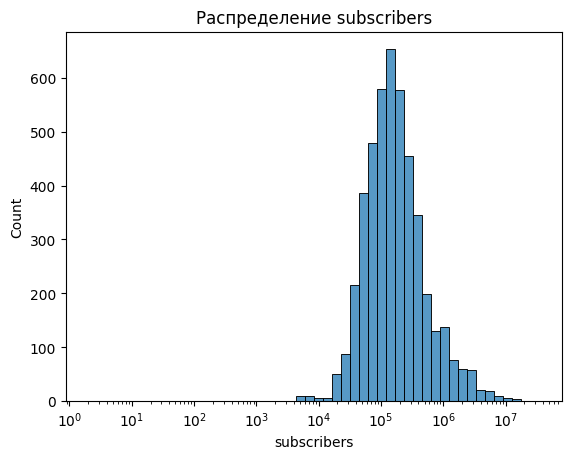

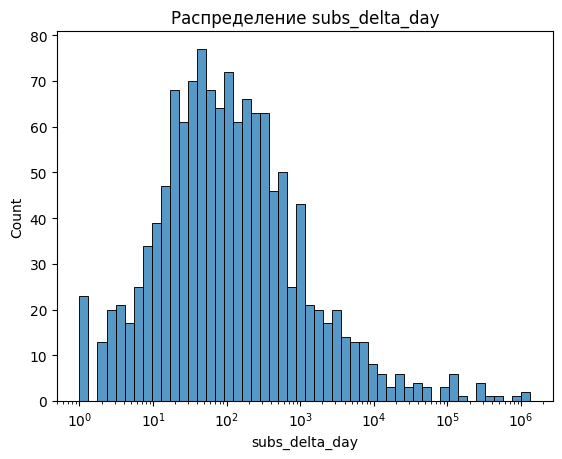

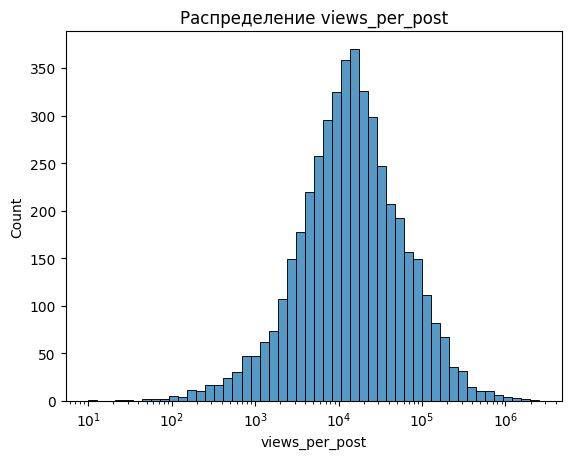

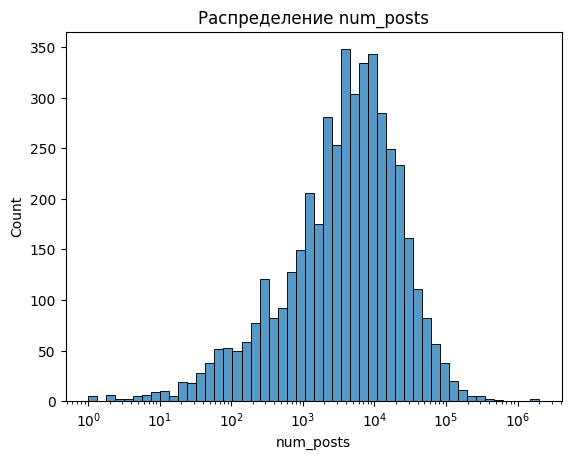

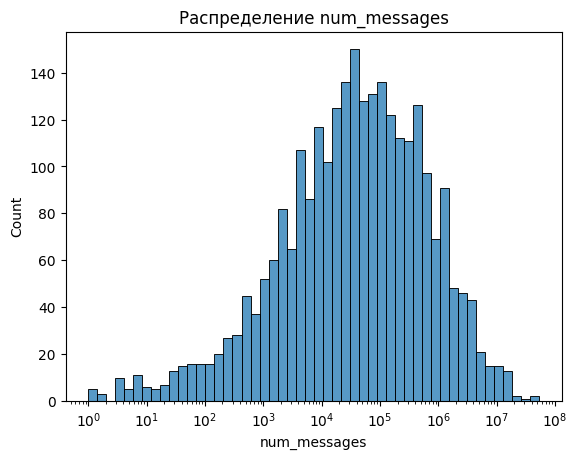

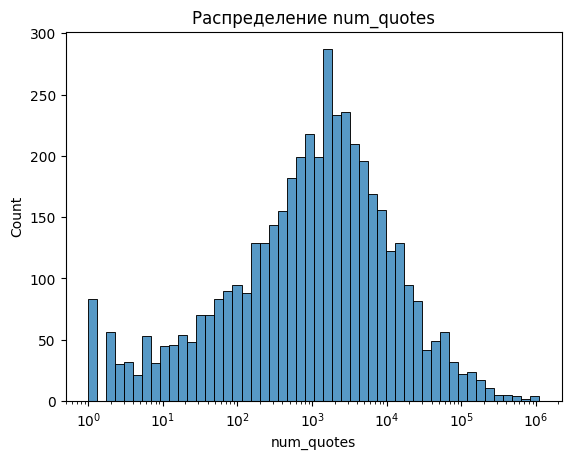

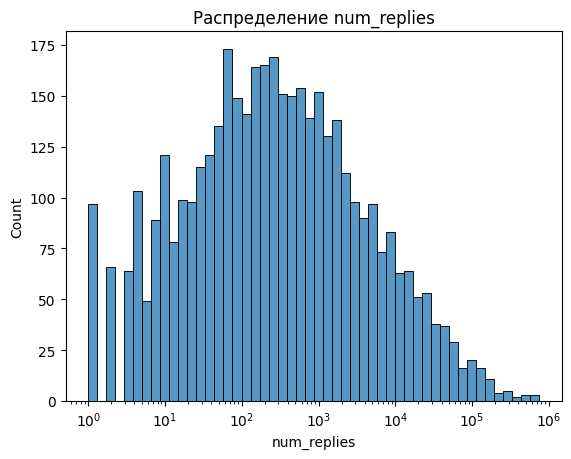

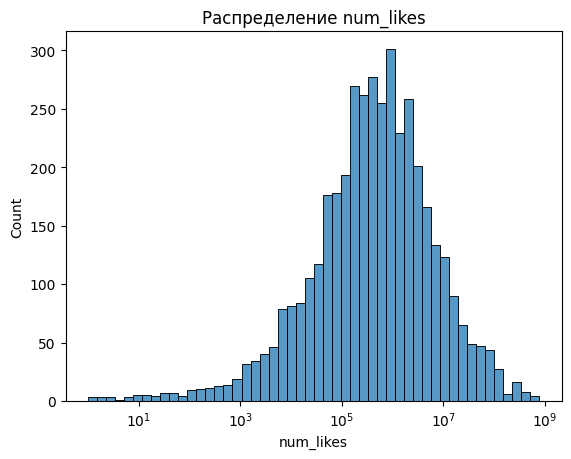

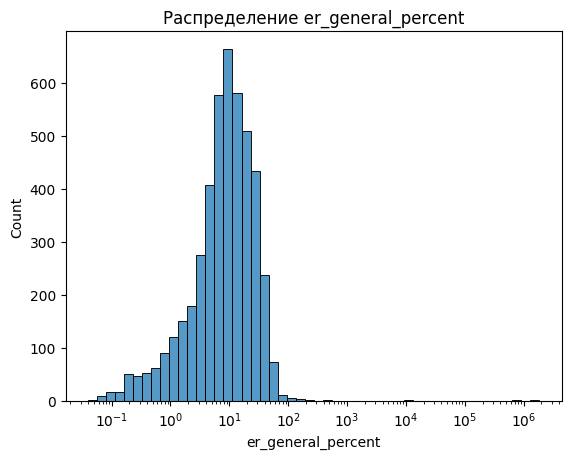

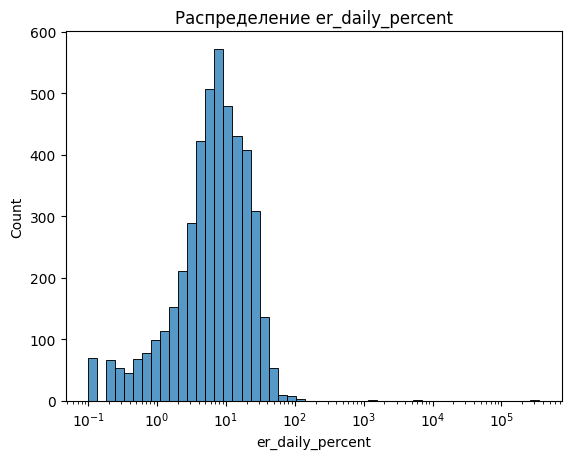

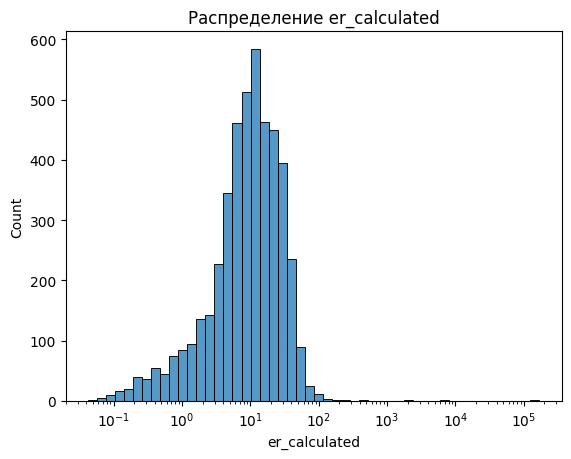

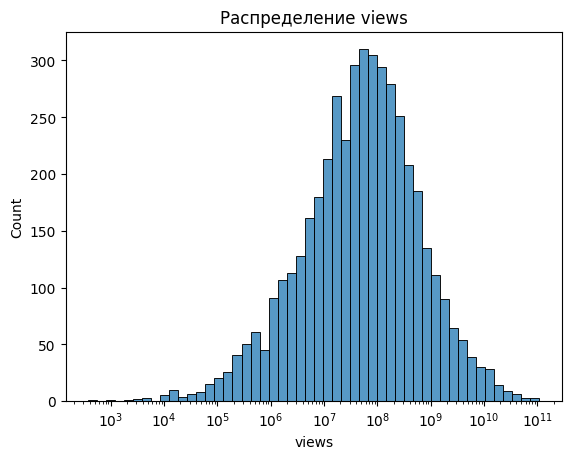

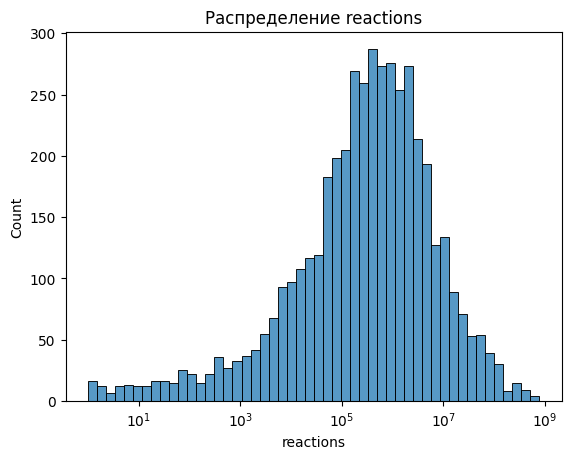

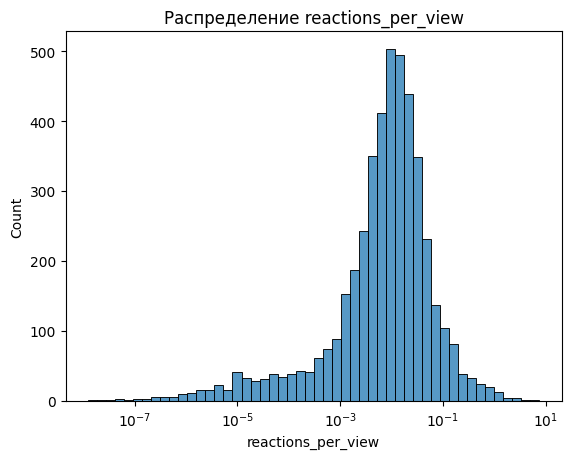

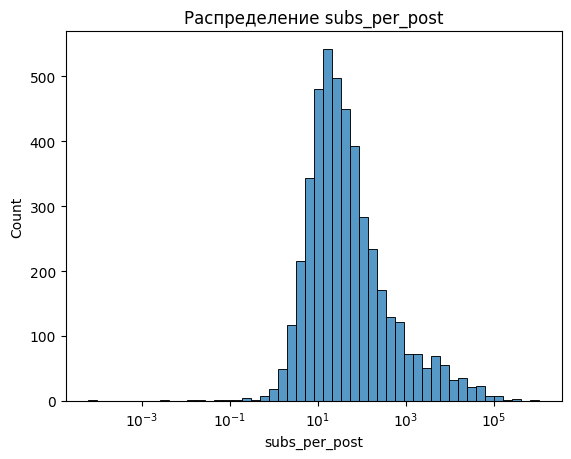

In [10]:
# Распределения числовых признаков в логарифмическом масштабе

numeric_cols = df.select_dtypes(include='number').columns.drop(["is_invite", "posts_showing"])

for col in numeric_cols:
    plt.figure()
    sns.histplot(df[col], bins=50, log_scale=True)
    plt.title(f'Распределение {col}')
    plt.show()

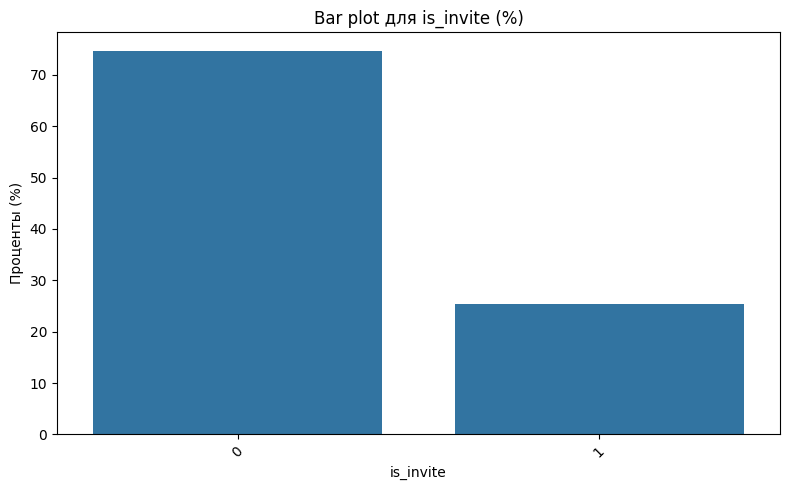

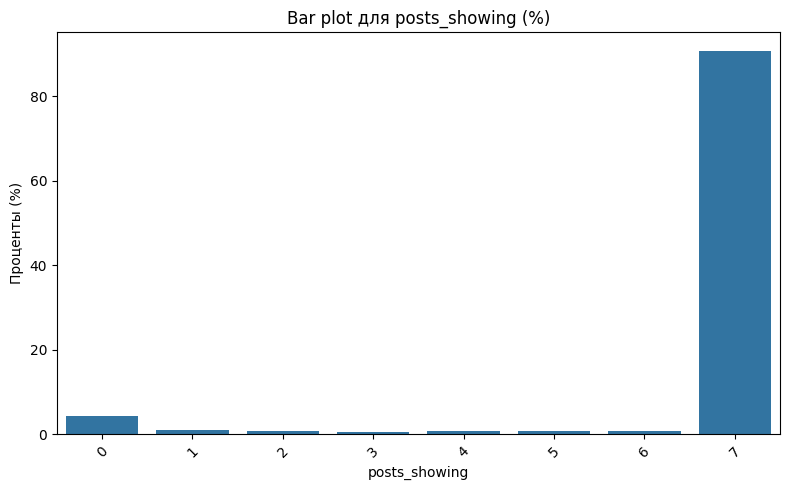

In [11]:
columns_to_plot = ['is_invite', 'posts_showing']

for col in columns_to_plot:
    plt.figure(figsize=(8, 5))

    counts = df[col].value_counts(normalize=True) * 100

    sns.barplot(x=counts.index, y=counts.values)

    plt.title(f'Bar plot для {col} (%)')
    plt.xlabel(col)
    plt.ylabel('Проценты (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()



In [12]:
cols = ["er_general_percent", "er_daily_percent", "er_calculated"]
df.loc[(df[cols] > 100).any(axis=1)]

,key,subscribers,subs_delta_day,views_per_post,num_posts,num_messages,num_quotes,num_replies,num_likes,description,posts_showing,last_post_content,last_post_datetime,language,name,er_general_percent,er_daily_percent,er_calculated,views,reactions,reactions_per_view,subs_per_post,is_invite
39,agrovitex,115038,204,128647,1400,0,64,57,531600,"Компания ""АгроВитЭкс"". Кормоинжиниринг - техно...",7,​​🐄Исследования адсорбента «Симбитокс» (премия...,2025-10-03 00:01:00,ru,АгроВитЭкс | Сельское хозяйство / Корма / Комб...,111.64,94.9,111.830004,180105800,531664,0.002952,82.17,0
73,alfabank,954906,-1030,1200723,1600,0,14800,10600,2300000,Оперативно рассказываем важные новости. Регист...,7,Каждый день дарим КЭШБЭК ДО 50% во «Вкусно — и...,2025-10-06 11:16:00,ru,Альфа-Банк,113.26,43.6,125.742534,1921156800,2314800,0.001205,596.81625,0
174,arsenmarkarian,180149,3,158484,1400,24900,760,159,822400,"Свободному и сильному, преследующему мечту",0,<NA>,NaT,ru,Арсен Маркарян Официальный,106.56,41.4,87.973844,221877600,848060,0.003822,128.677857,0
227,avtobozor_avtoeloni,2,-106607,3348,33100,97,881,641,0,Эълон бериш учун 👉 @this_admin га ёзингЭнг о...,7,Спарк 4 поз автомат сотилади❗️ 📅 йили 2022-23...,2025-10-07 11:26:00,ru,Авто Бозор | Расмий канал,2.91,2.6,167400.0,110818800,978,0.000009,0.00006,0
228,avtoyurist_uz,220,-142420,16962,18200,380400,2800,424,514700,🚘Барчаси автомобил ҳақида. 💰Реклама учун: @avt...,7,<NA>,2025-10-07 19:05:00,ru,AVTO YURIST,11.88,6426.4,7710.0,308708400,897900,0.002909,0.012088,0
368,bsweedy1,98470,-141,11906,288,76500,34,24,254700,"Реклама, заказ текста/песни и другие услуги @b...",7,"нормально вас туда налетело, не забывайте что ...",2025-10-05 18:09:00,ru,BSWEEDY,386.56,10.2,12.090992,3428928,331234,0.0966,341.909722,0
766,durov_russia,819963,8,727486,27,93300,7700,4500,347500,Канал для русскоязычной аудитории. Основной ка...,1,🏆 Студенты из Петербурга заняли первое место в...,2025-09-08 22:11:00,ru,Павел Дуров,109.23,72.4,88.721808,19642122,448500,0.022834,30369.0,0
958,finessthebest,145078,150,164016,2700,205500,650,632,1300000,"Основной канал 18+,реклама: @onemanagertgДанны...",7,<NA>,2025-10-03 15:32:00,ru,Юля Финесс,87.29,51.5,113.053668,442843200,1506150,0.003401,53.732593,0
985,flipnul,725277,-531,5699,2000,104100,192,100,762900,"Авторский блог на простом языке о том, как зар...",7,Вместительная коробка с крышкой для хранения ✔...,2025-10-08 10:05:00,ru,Flipnul,10335.67,0.9,0.785769,11398000,867192,0.076083,362.6385,0
1061,gazprombank,89577,-30,50391,2300,0,3000,2900,190800,Официальный канал Газпромбанка в Telegram. Зде...,7,🟤 ШИМУ — новый инструмент оценки денежно-креди...,2025-10-07 16:01:00,ru,Газпромбанк,41.40,129.1,56.254396,115899300,193800,0.001672,38.946522,0


In [13]:
rows = df.loc[(df[cols] > 200).any(axis=1)]

df = df.drop(index=rows.index)

In [14]:
get_stats()

,min,max,mean,std
subscribers,5_156.0,34_494_177.0,387_771.9,1_070_005.1
subs_delta_day,-31_189.0,1_339_457.0,1_432.3,31_763.7
views_per_post,0.0,2_529_398.0,38_102.6,96_117.8
num_posts,0.0,2_000_000.0,12_331.7,44_573.4
num_messages,0.0,53_400_000.0,333_002.9,1_724_865.5
num_quotes,0.0,1_100_000.0,9_958.4,45_281.0
num_replies,0.0,745_800.0,5_645.5,29_718.3
num_likes,0.0,773_900_000.0,6_743_022.6,34_740_374.9
posts_showing,0.0,7.0,6.5,1.7
er_general_percent,0.0,166.2,12.8,12.7


#### Корреляции числовых значений

Text(0.5, 1.0, 'Зависимость просмотров от числа подписчиков')

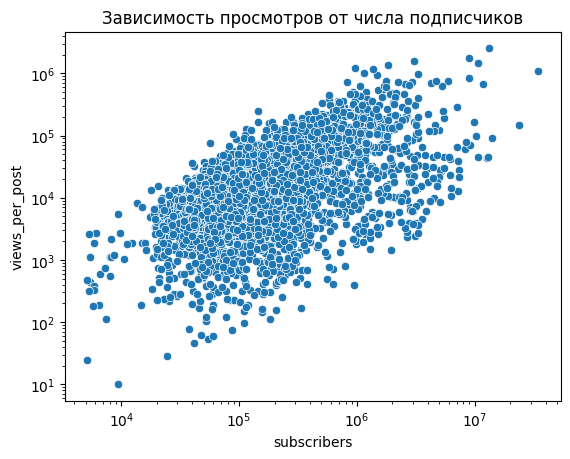

In [15]:
# Scatter plot числа просмотров от числа подписчиков в логарифмическом масштабе

sns.scatterplot(data=df, x='subscribers', y='views_per_post')
plt.xscale('log')
plt.yscale('log')
plt.title("Зависимость просмотров от числа подписчиков")


Text(0.5, 1.0, 'Зависимость изменения подписчиков за день от числа подписчиков')

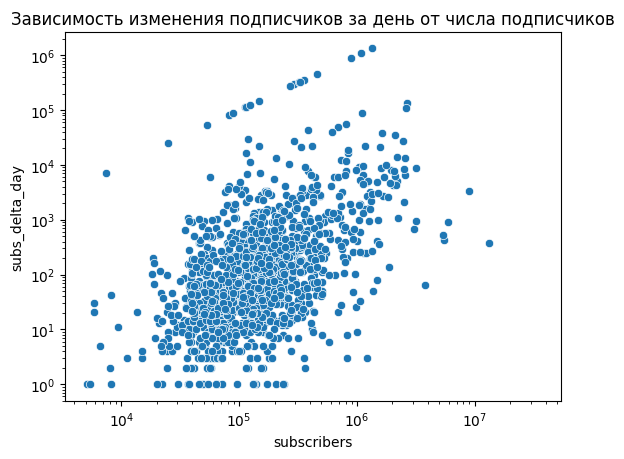

In [16]:
sns.scatterplot(data=df, x='subscribers', y='subs_delta_day')
plt.xscale('log')
plt.yscale('log')
plt.title("Зависимость изменения подписчиков за день от числа подписчиков")

In [17]:
df.nlargest(10, "subs_delta_day")

,key,subscribers,subs_delta_day,views_per_post,num_posts,num_messages,num_quotes,num_replies,num_likes,description,posts_showing,last_post_content,last_post_datetime,language,name,er_general_percent,er_daily_percent,er_calculated,views,reactions,reactions_per_view,subs_per_post,is_invite
4473,trendixgames,1339457,1339457,4870,406,0,37,18,110100,The official channel of Trendix web3 gameshttp...,0,<NA>,NaT,en,Trendix Games ♣️,0.27,0.1,0.36358,1977220,110137,0.055703,3299.155172,0
983,Flipkart_Loots_Deals_Online,1081440,1081440,12815,1,0,0,0,0,@Rkpatel190,0,<NA>,NaT,en,Shopping Loots Deals,1.18,1.0,1.184994,12815,0,0.0,1081440.0,0
2765,krypton_game,890030,890030,17569,41,0,69,4,744000,Experimenting the future of AI x crypto x gami...,0,<NA>,NaT,en,Krypton: AI X Gaming,3.22,1.5,1.973978,720329,744069,1.032957,21708.04878,0
4606,vchkogpu_ru,461704,461704,145474,31400,0,307900,266800,9400,<NA>,0,<NA>,NaT,<NA>,ВЧК-ОГПУ,26.12,4.8,31.508066,4567883600,317300,0.000069,14.703949,0
782,eco_uoos,354183,354183,5379,2100,0,10900,5200,665700,بررسی روزانه روند طلا و دلار با دکتر یونس کارد...,0,<NA>,NaT,fa,دکتر ترید | کریپتو سیگنال دلار طلا,0.55,0.9,1.518706,11295900,676600,0.059898,168.658571,0
3421,onlyfansmsbreewc,326757,326757,70228,233,0,50,10,130600,Telegram to @msbreewc_staff,0,<NA>,NaT,en,Msbreewc onlyfans,28.12,14.6,21.492424,16363124,130650,0.007984,1402.390558,0
3411,onepiecemmsub,324067,324067,19577,2600,58600,620,456,1000000,One Piece Myanmar Sub contact us @NashBelle,7,This message couldn't be displayed on your dev...,2025-09-23 19:43:00,en,One Piece MM Sub,7.36,4.3,6.041035,50900200,1059220,0.02081,124.641154,0
2267,invite_Sfp2f2FyM2owN2Zi,295039,295039,17000,0,0,1,0,0,<NA>,0,<NA>,NaT,<NA>,Dark Mystery Vault,9.18,5.2,5.76195,0,1,0.0,0.0,1
2721,knucklehit,271960,271960,88875,0,0,0,0,0,Добро пожаловать в Passion For Sports! Здесь в...,0,<NA>,NaT,ru,PFS,33.08,21.4,32.679438,0,0,0.0,0.0,0
3414,one_pieces_vf,146543,146543,5869,882,34100,1700,272,156400,l'anime one piece disponible dans ce canal a p...,0,<NA>,NaT,fr,One piece VF & VOSTFR,8.44,2.2,4.004968,5176458,192200,0.03713,166.148526,0


In [18]:
df = df.drop(df.loc[df["subs_delta_day"] == df["subscribers"]].index)

#### Языки

In [19]:
lang_freq = (
    df['language']
    .value_counts(normalize=False)
    .reset_index()
    .rename(columns={'index': 'language', 'count': 'frequency'})
    .sort_values(by='frequency', ascending=False)
)

lang_freq.head(10)

,language,frequency
0,ru,3224
1,en,458
2,uk,170
3,la,75
4,zh,66
5,fa,43
6,bg,37
7,es,35
8,am,31
9,ka,27


In [20]:
def map_lang(x):
    if pd.isna(x):
        return 'other'
    if x == 'ru':
        return 'ru'
    if x == 'en':
        return 'eng'
    return 'other'

df['lang_group'] = df['language'].apply(map_lang)

dummies = pd.get_dummies(df['lang_group'], prefix='lang').astype("Int64")
df = pd.concat([df, dummies], axis=1)

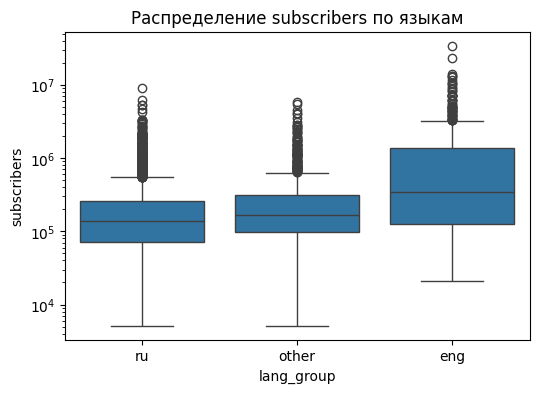

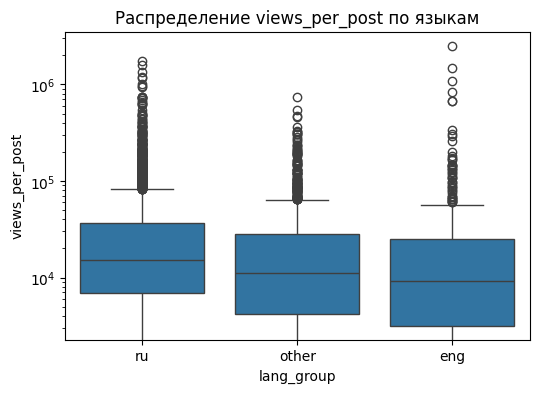

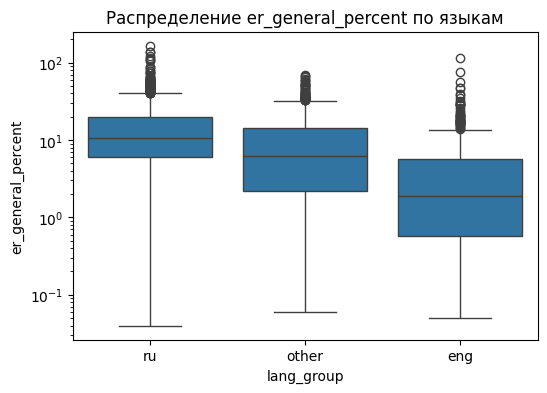

In [21]:
features = ['subscribers', 'views_per_post', 'er_general_percent']

for col in features:
    plt.figure(figsize=(6, 4))
    ax = sns.boxplot(x='lang_group', y=col, data=df)
    ax.set_yscale('log')
    plt.title(f"Распределение {col} по языкам")
    plt.show()

#### Матрица корреляций

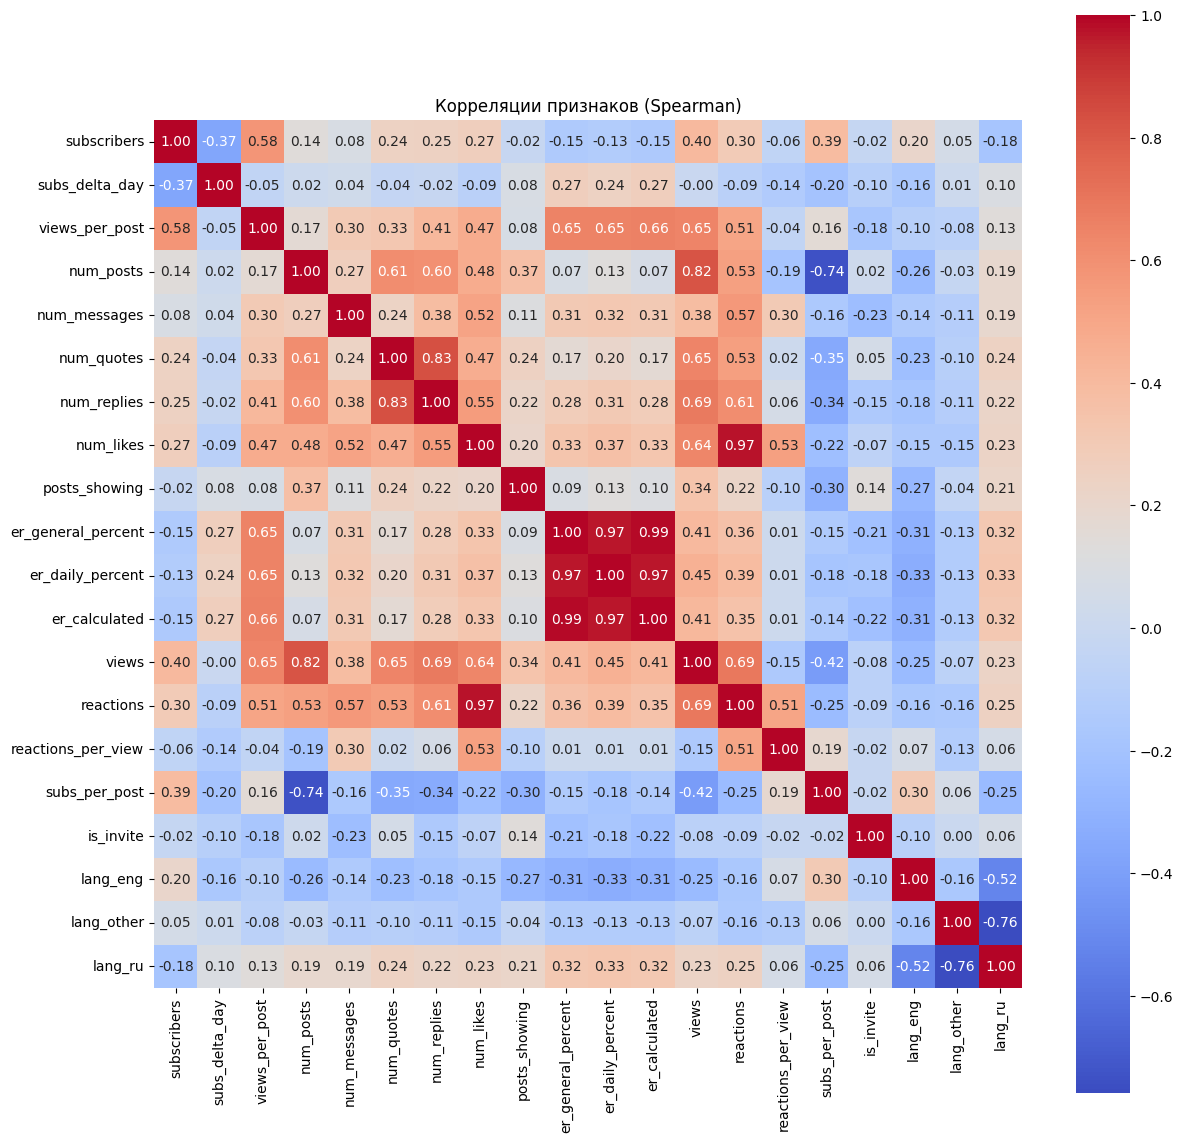

In [22]:
numeric_cols = df.select_dtypes(include='number').columns

df_plot = df[numeric_cols]

corr = df_plot.corr(method="spearman")
plt.figure(figsize=(14, 14))
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt=".2f", square=True)
plt.title("Корреляции признаков (Spearman)")
plt.show()

## Категории

In [23]:
df_cats = open_saved_table("data/final/edges.csv")

df_cats

,key,category
0,invite_TTyb3BxSUhgxZWI6,GIF и video
1,invite_TTyb3BxSUhgxZWI6,Новости
2,invite_30C82ymUXMFmYWJi,GIF и video
3,invite_30C82ymUXMFmYWJi,Новости
4,cheatkott,GIF и video
...,...,...
9788,civilcourt,Образование
9789,advokatsimutin,Юриспруденция
9790,lawandtattoo1,Бизнес и финансы
9791,lawandtattoo1,Спорт


In [24]:
df_merged = df.merge(df_cats, on='key', how='left')

df_merged.head(10)

,key,subscribers,subs_delta_day,views_per_post,num_posts,num_messages,num_quotes,num_replies,num_likes,description,posts_showing,last_post_content,last_post_datetime,language,name,er_general_percent,er_daily_percent,er_calculated,views,reactions,reactions_per_view,subs_per_post,is_invite,lang_group,lang_eng,lang_other,lang_ru,category
0,a4omg,539464,-703,113285,1100,0,14000,12600,30900000,Предложка - https://t.me/a4feedback_bot,7,🥭Настал сезон манго! В этом месяце выбрал его...,2025-10-05 14:50:00,ru,Влад Бумага A4,18.99,15.2,20.999548,124613500,30914000,0.248079,490.421818,0,ru,0,0,1,Авторский блог
1,a4omg,539464,-703,113285,1100,0,14000,12600,30900000,Предложка - https://t.me/a4feedback_bot,7,🥭Настал сезон манго! В этом месяце выбрал его...,2025-10-05 14:50:00,ru,Влад Бумага A4,18.99,15.2,20.999548,124613500,30914000,0.248079,490.421818,0,ru,0,0,1,Блогеры
2,a4omg,539464,-703,113285,1100,0,14000,12600,30900000,Предложка - https://t.me/a4feedback_bot,7,🥭Настал сезон манго! В этом месяце выбрал его...,2025-10-05 14:50:00,ru,Влад Бумага A4,18.99,15.2,20.999548,124613500,30914000,0.248079,490.421818,0,ru,0,0,1,GIF и video
3,a67bet,140477,50,24591,534,0,1,0,69700,🇧🇷🇧🇷🇧🇷O canal oficial 67bet atualiza regularm...,7,6️⃣7️⃣🅱️🔠🔠⚪️🔠🔠 🎁 Bônus diário de apostas cum...,2025-10-08 14:03:00,pt,67bet.cc | Canal Oficial ®,16.00,13.5,17.505357,13131594,69701,0.005308,263.065543,0,other,0,1,0,Прогнозы и ставки
4,aaaaaestheticsssss,280866,-123,3029,100,0,7,0,1400,<NA>,0,<NA>,NaT,<NA>,Aesthetics.,1.05,0.5,1.07845,302900,1407,0.004645,2808.66,0,other,0,1,0,Маркетплейсы
5,aaaredmarketing,394243,-510,23660,583,979,461,365,1000000,Лучшие маркетинговые истории со всего мира. Ка...,2,⚡️ Яндекс внёс изменения в свою «Конституцию»....,2025-09-23 13:23:00,ru,Красный маркетинг Гиязова,6.47,4.0,6.001375,13793780,1001440,0.072601,676.231561,0,ru,0,0,1,Маркетинг и реклама
6,aaaredmarketing,394243,-510,23660,583,979,461,365,1000000,Лучшие маркетинговые истории со всего мира. Ка...,2,⚡️ Яндекс внёс изменения в свою «Конституцию»....,2025-09-23 13:23:00,ru,Красный маркетинг Гиязова,6.47,4.0,6.001375,13793780,1001440,0.072601,676.231561,0,ru,0,0,1,Дизайн
7,aaaredmarketing,394243,-510,23660,583,979,461,365,1000000,Лучшие маркетинговые истории со всего мира. Ка...,2,⚡️ Яндекс внёс изменения в свою «Конституцию»....,2025-09-23 13:23:00,ru,Красный маркетинг Гиязова,6.47,4.0,6.001375,13793780,1001440,0.072601,676.231561,0,ru,0,0,1,Спорт
8,aacahb,47802,-1,19283,338,0,59,53,0,በዚህ ቻናል ላይ ስለ አዲስ አበባ ከተማ አስተዳደር ጤና ቢሮ የሰው ሃብት...,5,<NA>,2025-09-22 15:59:00,am,AACAHB HR,44.86,28.9,40.339316,6517654,59,0.000009,141.426036,0,other,0,1,0,Карьера
9,ab3army,305652,-44,40262,3900,32700,25200,16800,5600000,Офіційний канал Третього армійського корпусу З...,7,«Хто ти за званням? — Ніхто!» Це GoPro Третьо...,2025-10-07 18:32:00,uk,Третій армійський корпус,14.39,14.6,13.172497,157021800,5657900,0.036033,78.372308,0,other,0,1,0,Музыка


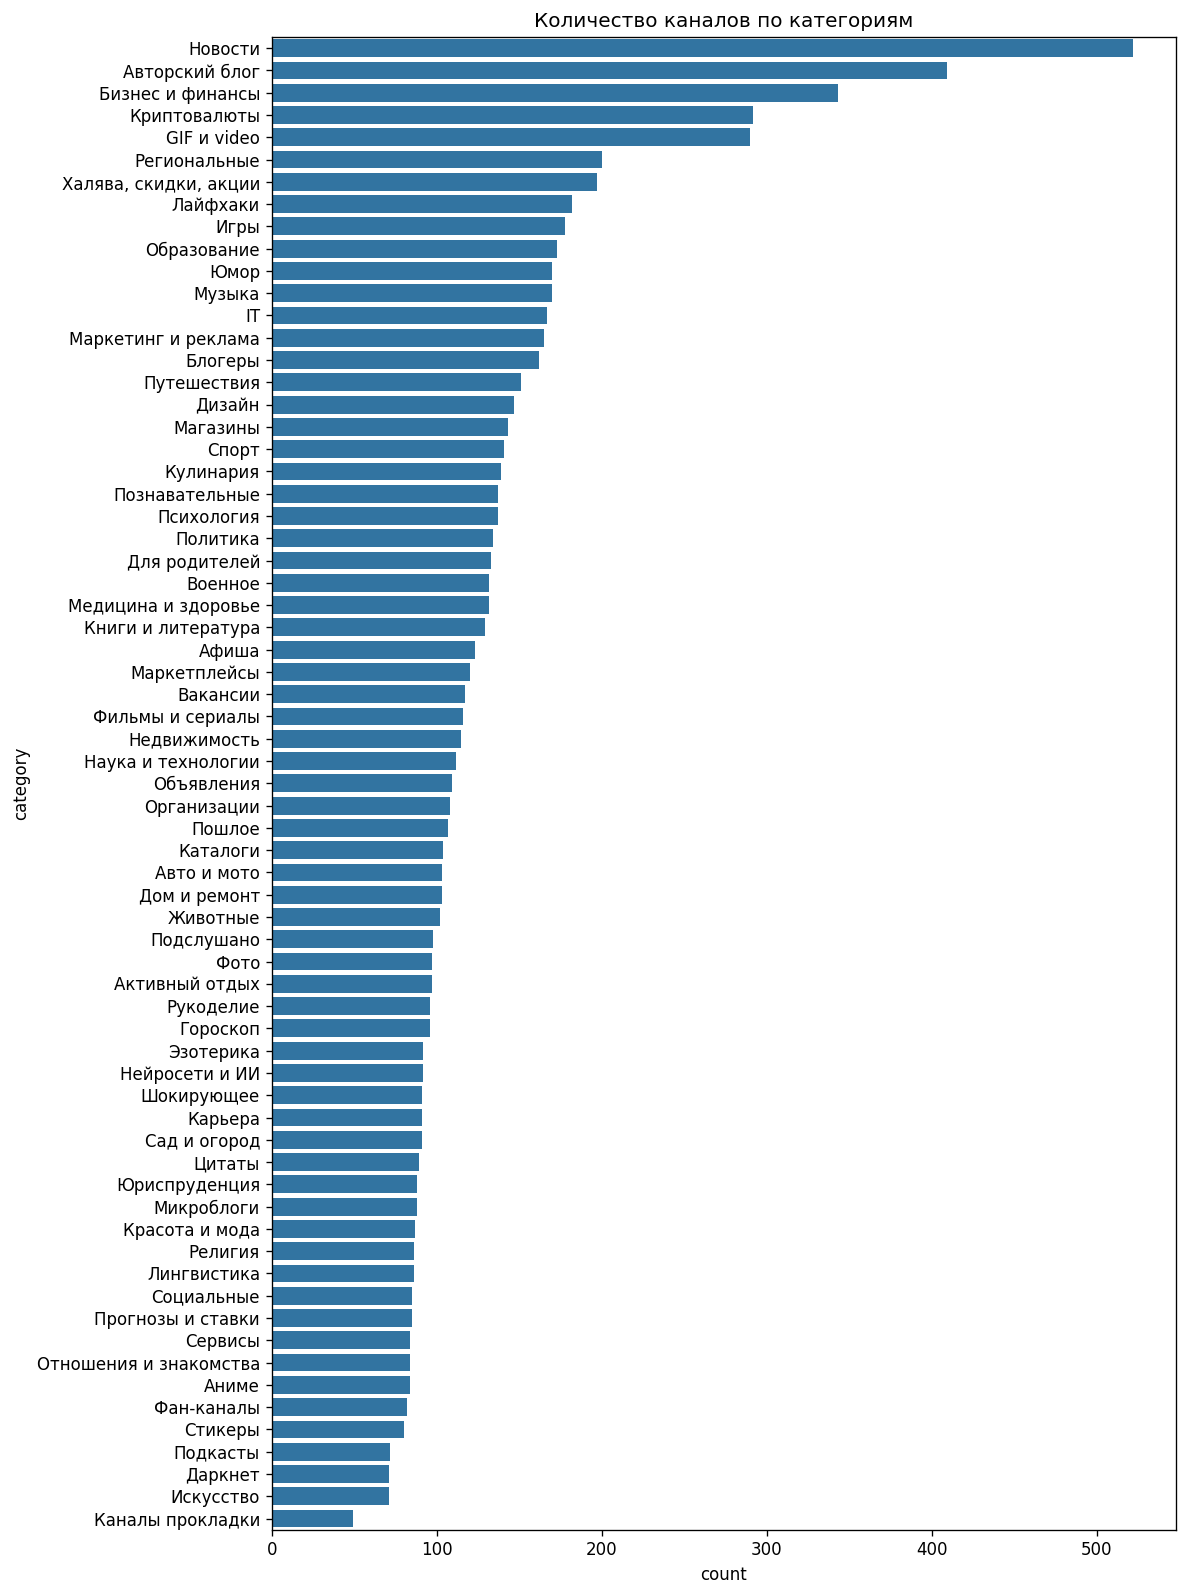

In [25]:
cats = df_merged['category'].value_counts().index

plt.figure(figsize=(10, 0.2*len(cats)), dpi=120)
sns.countplot(data=df_merged, y='category', order=cats)
plt.title("Количество каналов по категориям")
plt.tight_layout()

Хотя изначально брался топ-100 каналов из каждой категории, в некоторых категориях получилось больше каналов (потому что они были в топах других категорий), а в некоторых меньше (потому что каналы были заблокированы / содержали пропуски)


Text(0.5, 1.0, 'Распределение количества категорий на канал')

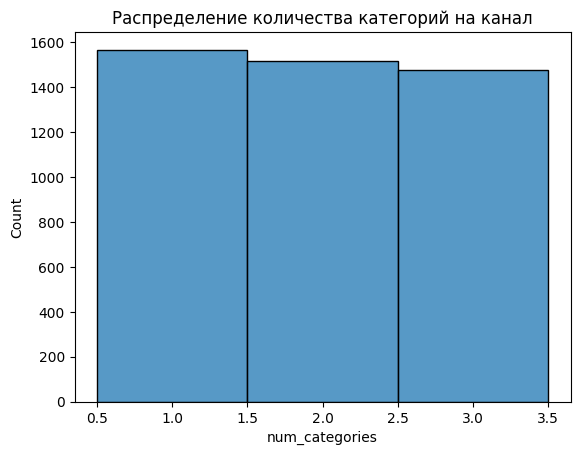

In [26]:
cat_counts = df_merged.groupby('key')['category'].nunique().reset_index(name='num_categories')
sns.histplot(cat_counts['num_categories'], bins=10, discrete=True)
plt.title("Распределение количества категорий на канал")

In [27]:
df = df.merge(cat_counts, on='key', how='left')

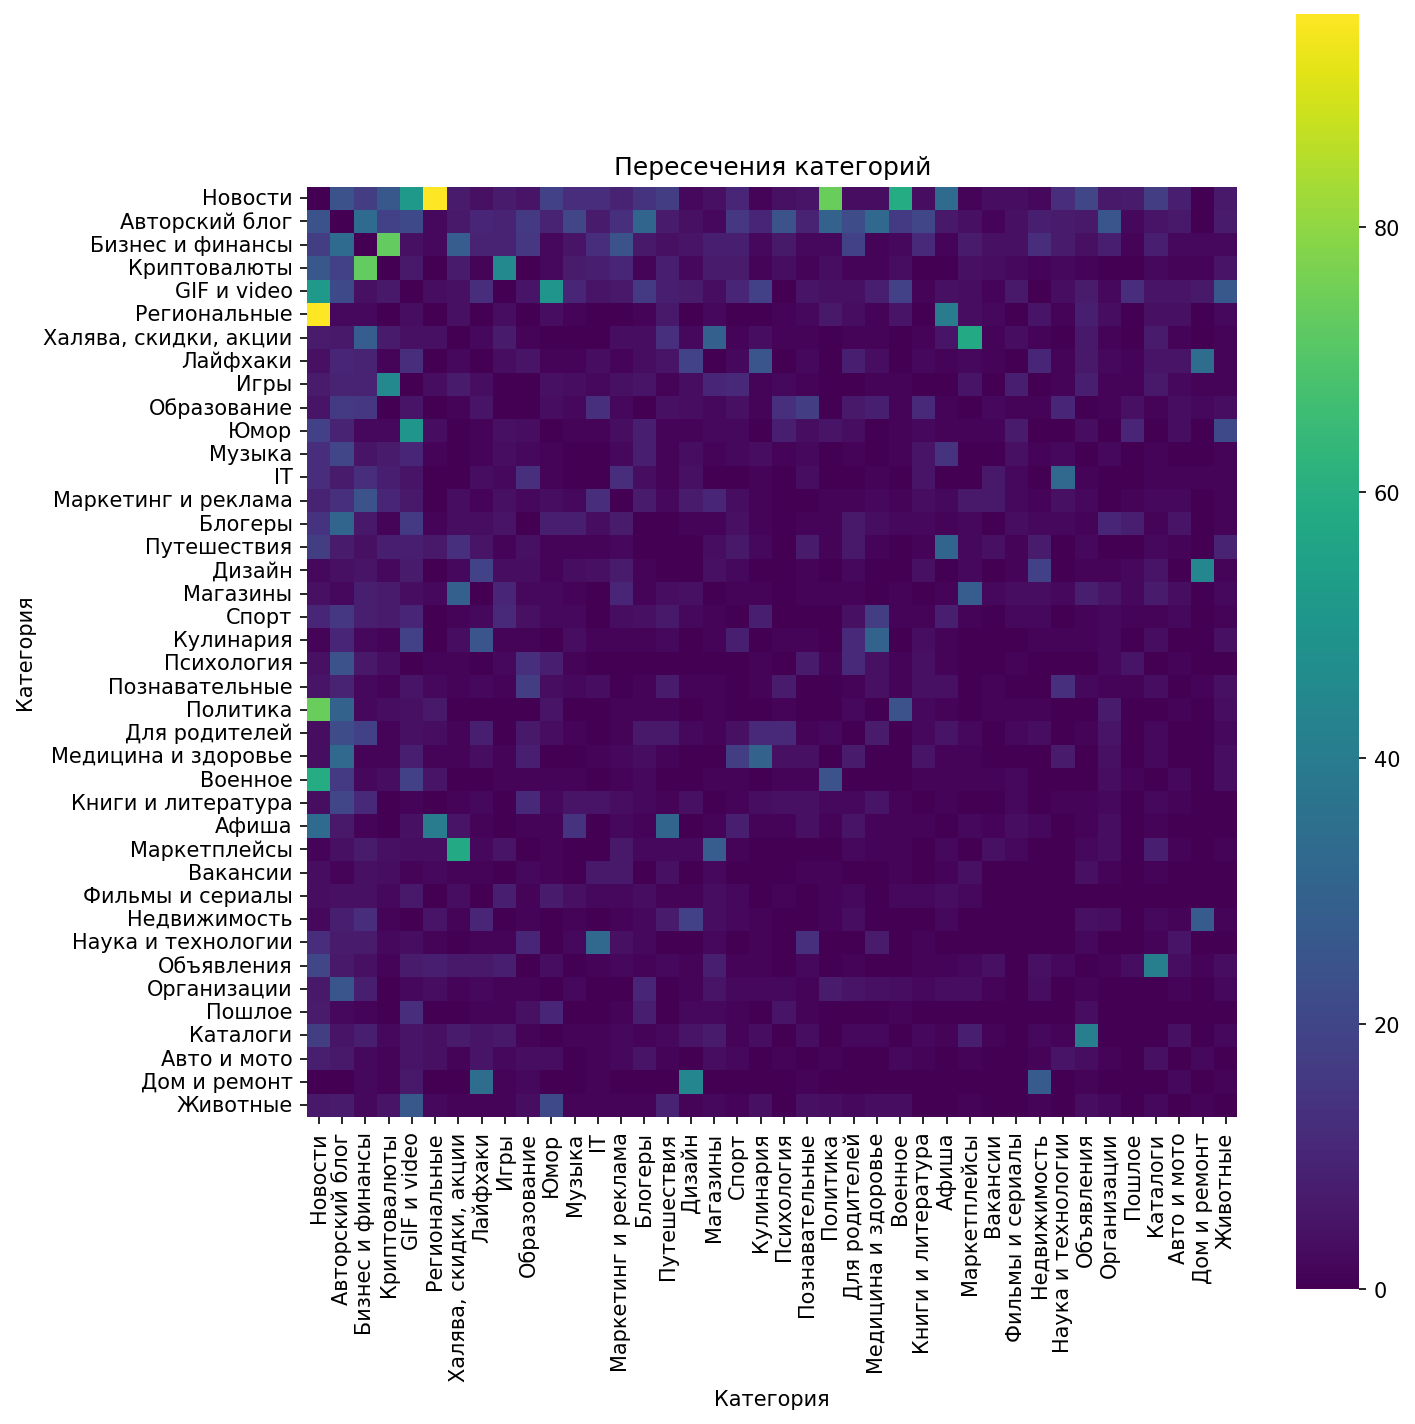

In [28]:
# Число общих каналов для топ 40 категорий
pairs = df_merged[['key','category']].drop_duplicates()
top = pairs['category'].value_counts().head(40).index
X = pd.crosstab(pairs.loc[pairs['category'].isin(top), 'category'],
                pairs.loc[pairs['category'].isin(top), 'key'])

co = X @ X.T
np.fill_diagonal(co.values, 0)

order = X.sum(axis=1).sort_values(ascending=False).index
co = co.loc[order, order]

n = co.shape[0]
plt.figure(figsize=(0.25*n, 0.25*n), dpi=150)
sns.heatmap(co, cmap='viridis', square=True)
plt.title("Пересечения категорий")
plt.xlabel("Категория"); plt.ylabel("Категория")
plt.tight_layout()

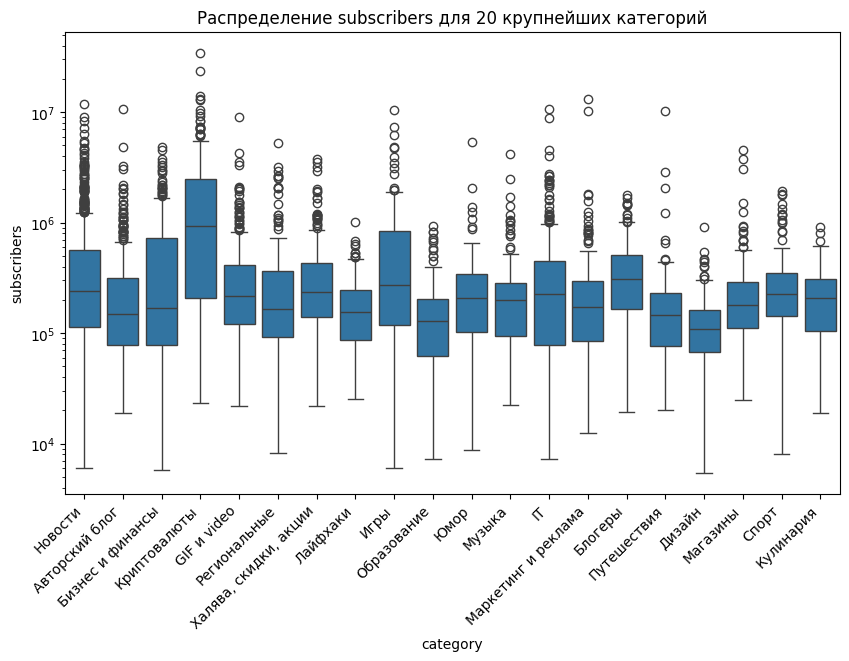

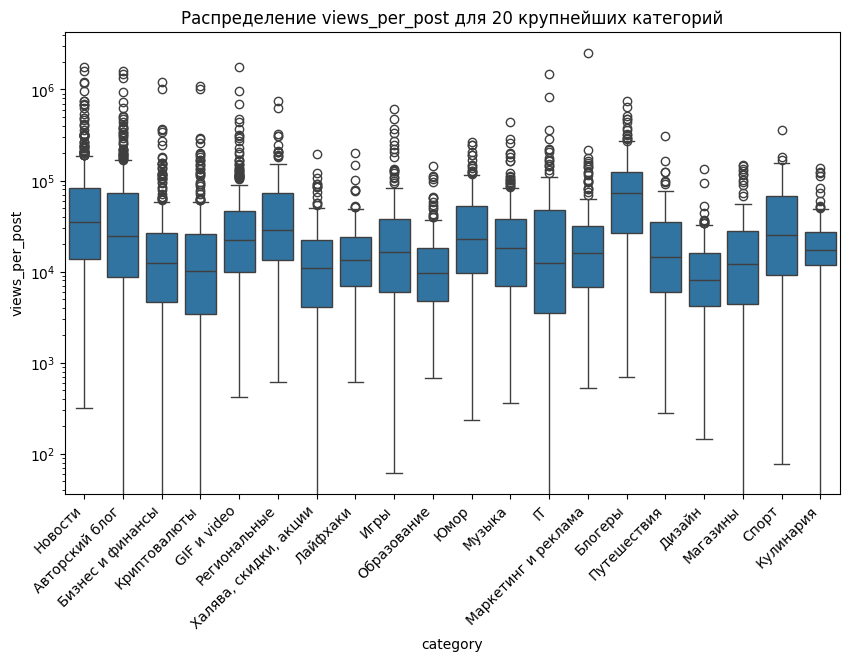

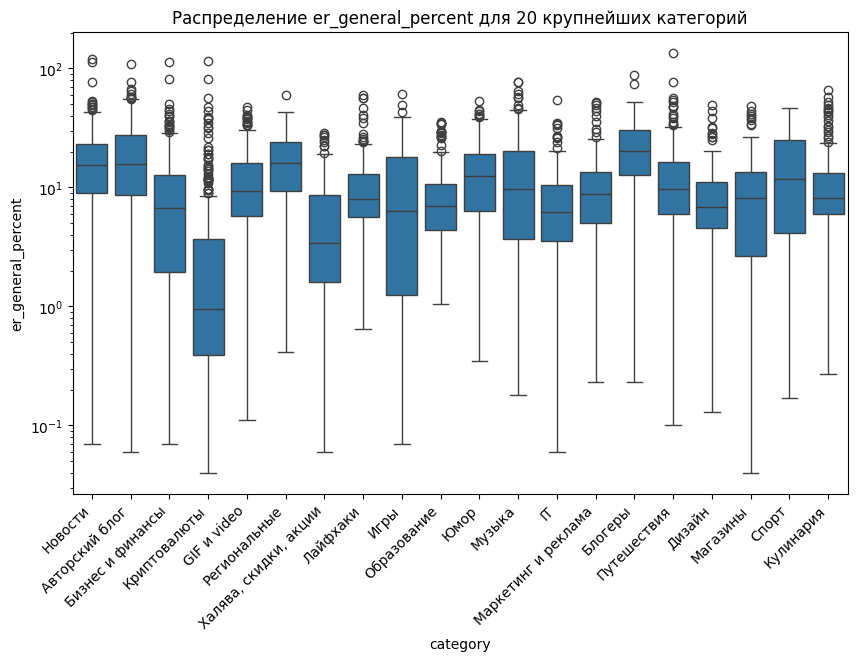

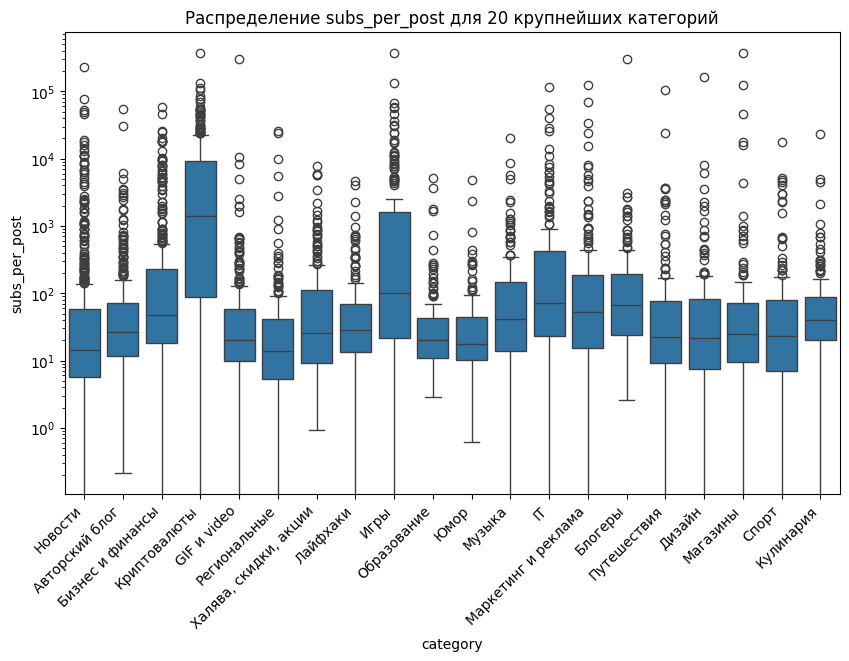

In [29]:
n = 20
top_cats = (
    df_merged['category']
    .value_counts()
    .head(n)
    .index
)

df_top = df_merged[df_merged['category'].isin(top_cats)]

features = ['subscribers', 'views_per_post', 'er_general_percent', 'subs_per_post']

for col in features:
    plt.figure(figsize=(10, 6))
    ax = sns.boxplot(
        data=df_top,
        x='category',
        y=col,
        order=top_cats
    )
    ax.set_yscale('log')
    plt.xticks(rotation=45, ha='right')

    plt.title(f"Распределение {col} для {n} крупнейших категорий")
    plt.show()


In [30]:
lang_by_cat = (
    df_merged
    .groupby(['category', 'lang_group'])
    .size()
    .reset_index(name='count')
)

# Нормализуем внутри категории
lang_by_cat['percent'] = (
    lang_by_cat.groupby('category')['count']
    .transform(lambda x: x / x.sum() * 100)
)


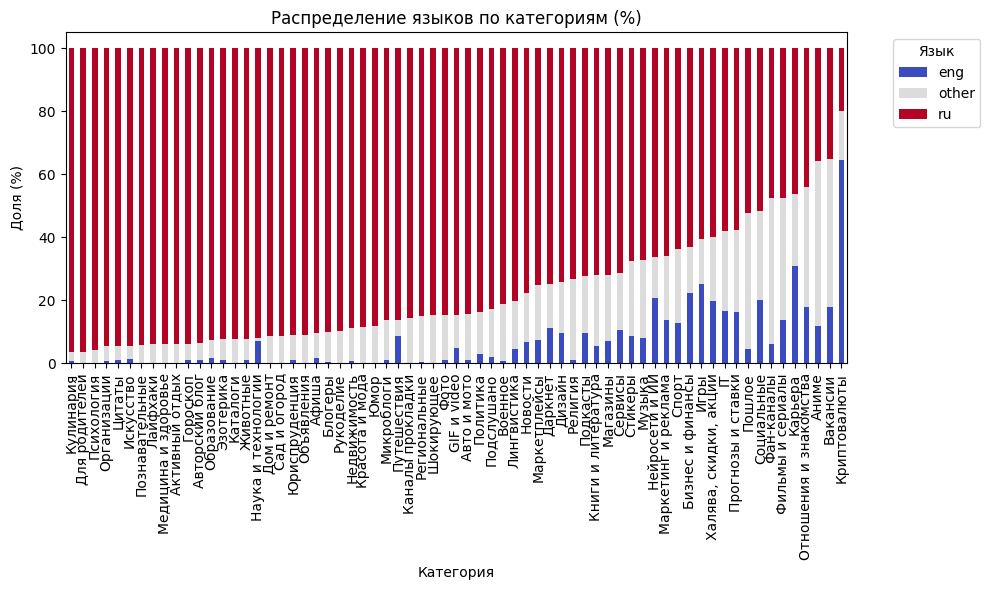

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

pivot = lang_by_cat.pivot(index='category', columns='lang_group', values='percent').fillna(0)
pivot = pivot.sort_values(by='ru', ascending=False)

pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='coolwarm'
)
plt.title("Распределение языков по категориям (%)")
plt.ylabel("Доля (%)")
plt.xlabel("Категория")
plt.legend(title="Язык", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# Машинное обучение с учителем

Задача: предсказывать язык (ru/eng) по параметрам 'subs_per_post', 'er_daily_percent', 'num_categories': с помощью логистической регрессии

In [32]:
# Удаление других языков
if {'lang_other'}.issubset(df.columns):
  df = df.drop(df.loc[df["lang_other"] == 1].index).drop(columns = ["lang_other"])

In [33]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils import resample


features = ['subs_per_post', 'er_daily_percent', "num_categories"]
target = 'lang_eng'

# Балансировка выборки (undersampling)
majority = df[df[target] == 0]
minority = df[df[target] == 1]

majority_downsampled = resample(
    majority,
    replace=False,
    n_samples=len(minority),
    random_state=42
)

df_balanced = pd.concat([majority_downsampled, minority])

X = df_balanced[features]
y = df_balanced[target]


# Разделение на train/val/test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Baseline
threshold = X_train['er_daily_percent'].median()
y_baseline = (X_test['er_daily_percent'] > threshold).astype(int)

print("Baseline metrics: ")
print(classification_report(y_test, y_baseline))
print("Confusion matrix:\n", confusion_matrix(y_test, y_baseline))

Baseline metrics: 
              precision    recall  f1-score   support

         0.0       0.25      0.25      0.25        69
         1.0       0.25      0.25      0.25        69

    accuracy                           0.25       138
   macro avg       0.25      0.25      0.25       138
weighted avg       0.25      0.25      0.25       138

Confusion matrix:
 [[17 52]
 [52 17]]


In [34]:
# Логистическая регрессия + GridSearch
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear']
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    param_grid,
    cv=5,
    scoring='f1_macro'
)
grid.fit(X_train_scaled, y_train)

print("Best params:", grid.best_params_)

Best params: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}


In [35]:
# Финальная модель
model = LogisticRegression(**grid.best_params_, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Предсказания
y_train_pred = model.predict(X_train_scaled)
y_val_pred = model.predict(X_val_scaled)
y_test_pred = model.predict(X_test_scaled)

# Метрики
def show_metrics(y_true, y_pred, label="Dataset"):
    print(f"{label} metrics")
    print(classification_report(y_true, y_pred))
    print("Confusion matrix:\n", confusion_matrix(y_true, y_pred))

show_metrics(y_train, y_train_pred, "Train")
show_metrics(y_val, y_val_pred, "Validation")
show_metrics(y_test, y_test_pred, "Test")

# Важность признаков
coef_df = pd.DataFrame({
    'feature': features,
    'coef': model.coef_[0]
}).sort_values(by='coef', ascending=False)
print("Feature importance (logreg coefficients):")
print(coef_df)

Train metrics
              precision    recall  f1-score   support

         0.0       0.80      0.76      0.78       320
         1.0       0.77      0.81      0.79       321

    accuracy                           0.78       641
   macro avg       0.79      0.78      0.78       641
weighted avg       0.79      0.78      0.78       641

Confusion matrix:
 [[242  78]
 [ 60 261]]
Validation metrics
              precision    recall  f1-score   support

         0.0       0.78      0.78      0.78        69
         1.0       0.78      0.78      0.78        68

    accuracy                           0.78       137
   macro avg       0.78      0.78      0.78       137
weighted avg       0.78      0.78      0.78       137

Confusion matrix:
 [[54 15]
 [15 53]]
Test metrics
              precision    recall  f1-score   support

         0.0       0.82      0.61      0.70        69
         1.0       0.69      0.87      0.77        69

    accuracy                           0.74       138
  

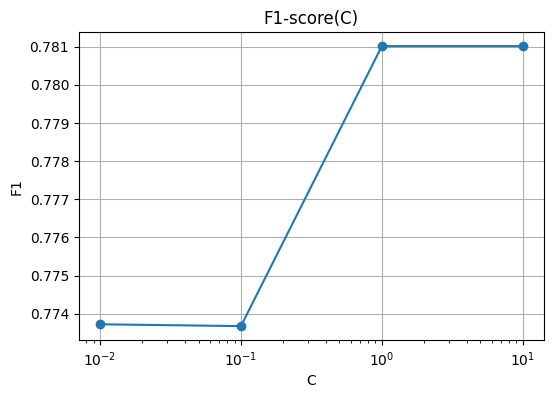

In [36]:
# График F1 от регуляризации C
f1_scores = []
C_values = [0.01, 0.1, 1, 10]
for C in C_values:
    clf = LogisticRegression(C=C, max_iter=1000, penalty='l2', solver='lbfgs')
    clf.fit(X_train_scaled, y_train)
    y_val_pred = clf.predict(X_val_scaled)
    f1_scores.append(f1_score(y_val, y_val_pred, average='macro'))

plt.figure(figsize=(6,4))
plt.plot(C_values, f1_scores, marker='o')
plt.xscale('log')
plt.xlabel("C")
plt.ylabel("F1")
plt.title("F1-score(C)")
plt.grid(True)
plt.show()

#### Своя реализация

Используются градиентный спуск, L2 регуляризация и гиперпараметры learning_rate, num_iter, C


In [37]:
class LogisticRegression:
    def __init__(self, learning_rate=0.01, num_iter=1000, C=1.0):
        self.lr = learning_rate
        self.num_iter = num_iter
        self.C = C
        self.w = None
        self.b = None

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros((n_features,1))
        self.b = 0

        for _ in range(self.num_iter):
            z = X @ self.w + self.b
            y_pred = self.sigmoid(z)

            dw = (1/n_samples) * (X.T @ (y_pred - y)) + (1/self.C) * self.w
            db = (1/n_samples) * np.sum(y_pred - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict_prob(self, X):
        return self.sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_prob(X) >= threshold).astype(int)

In [38]:
y_train_np = y_train.values.reshape(-1,1).astype(np.float64)

# Наивный перебор гиперпараметров
best_f1 = 0
best_params = {}
learning_rates = [0.01, 0.05, 0.1]
num_iters = [500, 1000, 2000]
C_values = [0.1, 1, 10]

for lr in learning_rates:
    for n_iter in num_iters:
        for C in C_values:
            clf = LogisticRegression(learning_rate=lr, num_iter=n_iter, C=C)
            clf.fit(X_train_scaled, y_train_np)
            y_val_pred = clf.predict(X_val_scaled)
            f1 = f1_score(y_val, y_val_pred, average='macro')

            if f1 > best_f1:
                best_f1 = f1
                best_params = {'learning_rate': lr, 'num_iter': n_iter, 'C': C}
                best_model = clf

print("Best params:", best_params)
print("Best F1 on val:", best_f1)

Best params: {'learning_rate': 0.01, 'num_iter': 500, 'C': 10}
Best F1 on val: 0.7737226277372263


In [39]:
# Оценка на train/val/test
for X_set, y_set, label in zip([X_train_scaled, X_val_scaled, X_test_scaled],
                               [y_train, y_val, y_test],
                               ['Train','Validation','Test']):
    y_pred = best_model.predict(X_set)
    print(f"{label} metrics")
    print(classification_report(y_set, y_pred))
    print("Confusion matrix:\n", confusion_matrix(y_set, y_pred))

Train metrics
              precision    recall  f1-score   support

         0.0       0.78      0.70      0.74       320
         1.0       0.73      0.80      0.76       321

    accuracy                           0.75       641
   macro avg       0.75      0.75      0.75       641
weighted avg       0.75      0.75      0.75       641

Confusion matrix:
 [[225  95]
 [ 65 256]]
Validation metrics
              precision    recall  f1-score   support

         0.0       0.78      0.77      0.77        69
         1.0       0.77      0.78      0.77        68

    accuracy                           0.77       137
   macro avg       0.77      0.77      0.77       137
weighted avg       0.77      0.77      0.77       137

Confusion matrix:
 [[53 16]
 [15 53]]
Test metrics
              precision    recall  f1-score   support

         0.0       0.81      0.57      0.67        69
         1.0       0.67      0.87      0.75        69

    accuracy                           0.72       138
  

In [40]:
# Сравнение с sklearn
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression(C=best_params['C'], max_iter=best_params['num_iter'], solver='lbfgs')
sk_model.fit(X_train_scaled, y_train.ravel())
y_test_sk = sk_model.predict(X_test_scaled)
print("sklearn LogisticRegression on Test")
print(classification_report(y_test, y_test_sk))

sklearn LogisticRegression on Test
              precision    recall  f1-score   support

         0.0       0.82      0.61      0.70        69
         1.0       0.69      0.87      0.77        69

    accuracy                           0.74       138
   macro avg       0.76      0.74      0.73       138
weighted avg       0.76      0.74      0.73       138



/tmp/ipykernel_2175/2952625168.py:5: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  sk_model.fit(X_train_scaled, y_train.ravel())


# Машинное обучение без учителя

Оставим для кластеризации только самые важные для характеристики поведения канала столбцы:
- Подписчики: subscribers
- Число постов: num_posts
- Вовлеченность: er_general_percent, reactions_per_view

In [41]:
if {'lang_other'}.issubset(df.columns):
  df = df.drop(df.loc[df["lang_other"] == 1].index).drop(columns = ["lang_other"])

features = [
    "subscribers",
    "num_posts",
    "er_general_percent",
    "reactions_per_view"
]

Проверим, что нет сильных корреляций между признаками

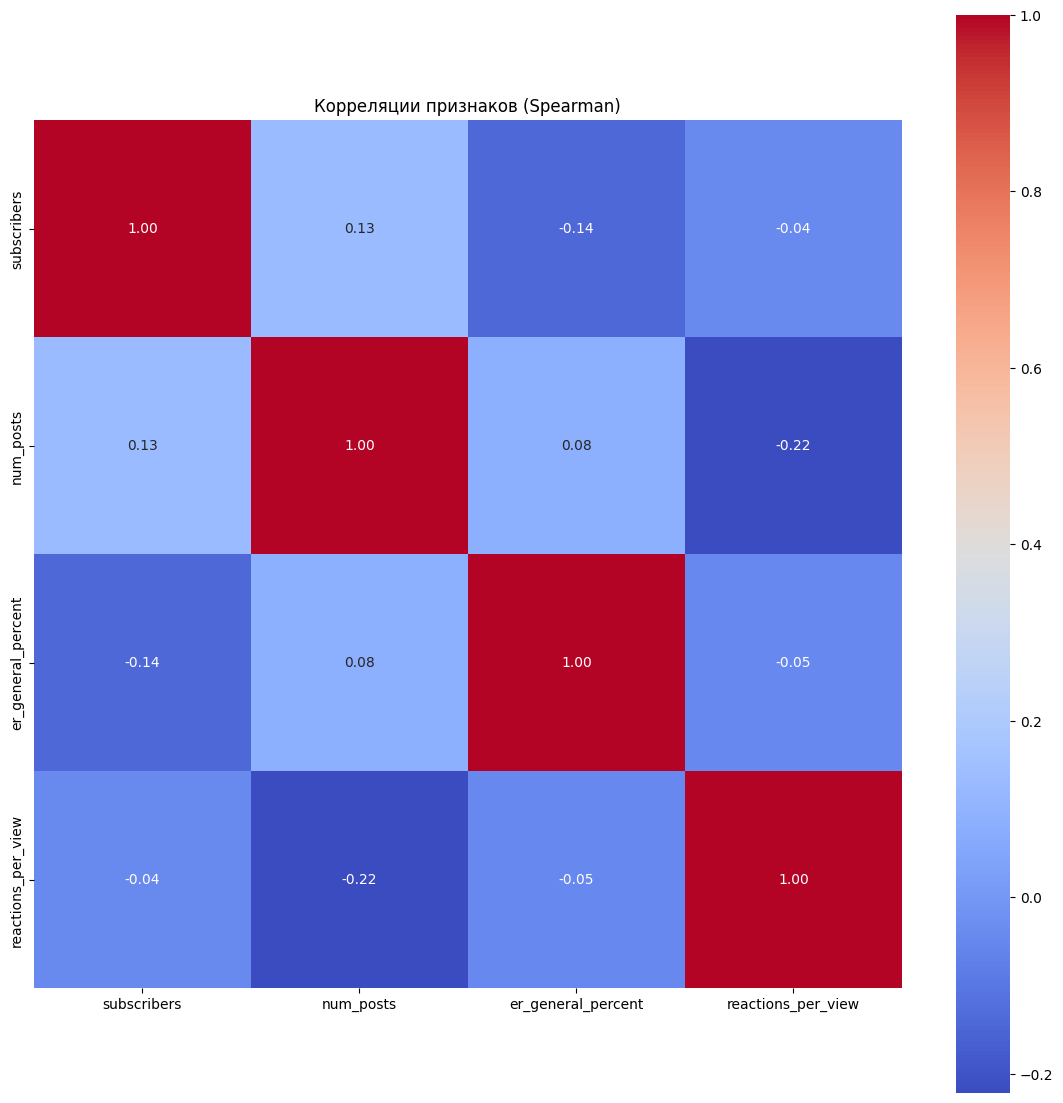

In [42]:
df_plot = df[features]

corr = df_plot.corr(method="spearman")
plt.figure(figsize=(14, 14))
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt=".2f", square=True)
plt.title("Корреляции признаков (Spearman)")
plt.show()

In [43]:
pd.DataFrame({
    "dtype": df_plot.dtypes,
    "missing": df_plot.isna().sum()
})

,dtype,missing
subscribers,Int64,0
num_posts,Int64,0
er_general_percent,float64,0
reactions_per_view,Float64,0


Стандартизация

!!! важно: данные логонормальные и их надо логарифмировать (чтобы не думать несколько недель над странным видом графиков)

In [44]:
from sklearn.preprocessing import StandardScaler

X_log = df_plot.astype("float64").copy().fillna(0)

features_to_log = [
    "subscribers",
    "num_posts",
    "reactions_per_view"
]
for col in features_to_log:
    X_log[col] = np.log1p(X_log[col].to_numpy())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

In [45]:
pd.DataFrame({
    "dtype": X_scaled_df.dtypes,
    "missing": X_scaled_df.isna().sum()
})

,dtype,missing
subscribers,float64,0
num_posts,float64,0
er_general_percent,float64,0
reactions_per_view,float64,0


In [46]:
X_scaled_df.describe().T

,count,mean,std,min,25%,50%,75%,max
subscribers,3682.0,-1.026640e-15,1.000136,-3.034942,-0.683799,-0.095300,0.519530,4.671145
num_posts,3682.0,6.175276e-17,1.000136,-3.960751,-0.439990,0.169398,0.653953,3.162707
er_general_percent,3682.0,-6.175276e-17,1.000136,-1.025621,-0.659855,-0.292548,0.395862,11.769261
reactions_per_view,3682.0,-4.824435e-17,1.000136,-0.340816,-0.308649,-0.239401,-0.086472,18.102178


### baseline

выделим в отдельный кластер каналы, у которых число подписчиков > среднего, а ER < среднего

In [47]:
df["cluster_baseline"] = np.where(
    (df["subscribers"] > df["subscribers"].mean()) & (df["er_general_percent"] < df["er_general_percent"].mean()),
    1, 0)

#### K-means

Найдем оптимальное количество кластеров

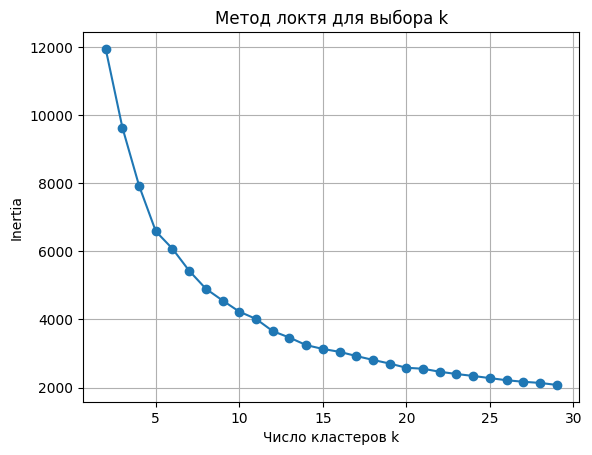

In [48]:
from sklearn.cluster import KMeans

inertias = []
K = range(2, 30)
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(K, inertias, marker="o")
plt.xlabel("Число кластеров k")
plt.ylabel("Inertia")
plt.title("Метод локтя для выбора k")
plt.grid(True)
plt.show()


Этот метод в данном случае не помогает выбрать кластеры

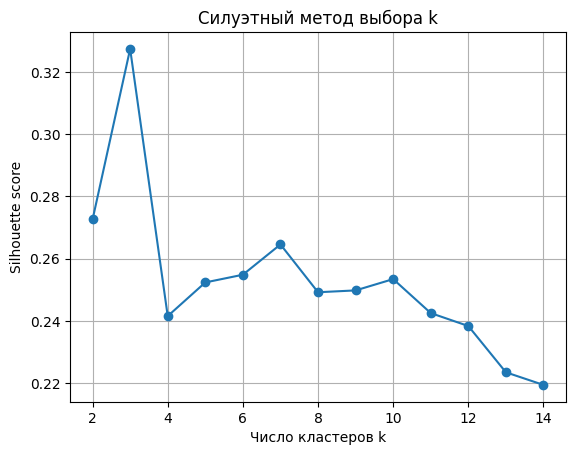

In [49]:
from sklearn.metrics import silhouette_score

scores = []
for k in range(2, 15):
    km = KMeans(n_clusters=k, random_state=12, n_init="auto").fit(X_scaled)
    labels = km.labels_
    score = silhouette_score(X_scaled, labels)
    scores.append(score)

plt.plot(range(2, 15), scores, marker="o")
plt.xlabel("Число кластеров k")
plt.ylabel("Silhouette score")
plt.title("Силуэтный метод выбора k")
plt.grid(True)
plt.show()


берем k при котором Silhouette score максимален

In [50]:
k = 2

kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
kmeans.fit(X_scaled)

df["cluster_kmeans"] = kmeans.labels_

In [51]:
df["cluster_kmeans"].value_counts().sort_index()

,count
cluster_kmeans,
0,503
1,3179


In [52]:
# Как выглядит средний представитель каждого кластера

kmeans_profile = df.groupby("cluster_kmeans")[features].mean().T
kmeans_profile


cluster_kmeans,0,1
subscribers,1320644.703777,255387.891475
num_posts,357.586481,13747.92419
er_general_percent,8.962724,14.054794
reactions_per_view,0.185586,0.017354


#### PCA

In [53]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_scaled)

df["pca1"] = Z[:, 0]
df["pca2"] = Z[:, 1]


In [54]:
def plot_pca(cluster_name):
  plt.figure(figsize=(8, 6))
  sns.scatterplot(
      data=df,
      x="pca1", y="pca2",
      hue=f"cluster_{cluster_name}",
      palette="tab10",
      s=25, alpha=0.8
  )
  plt.title(f"{cluster_name} clusters on PCA projection")
  plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
  plt.show()

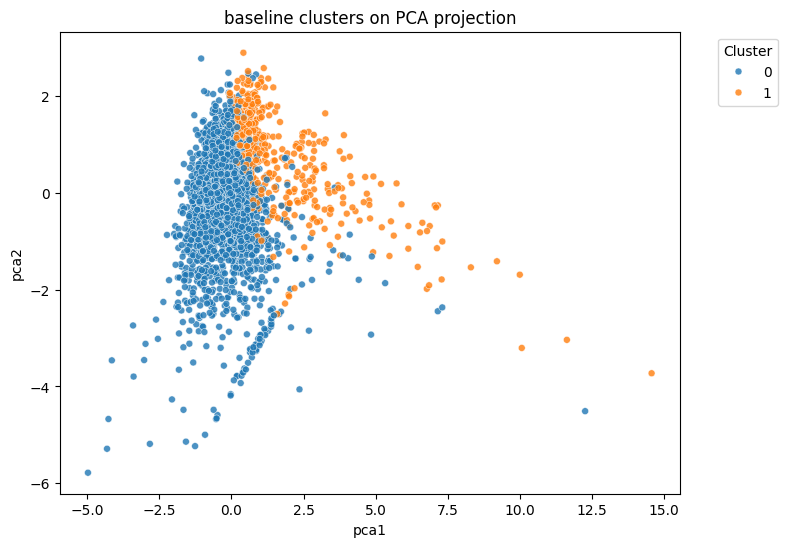

In [55]:
plot_pca("baseline")

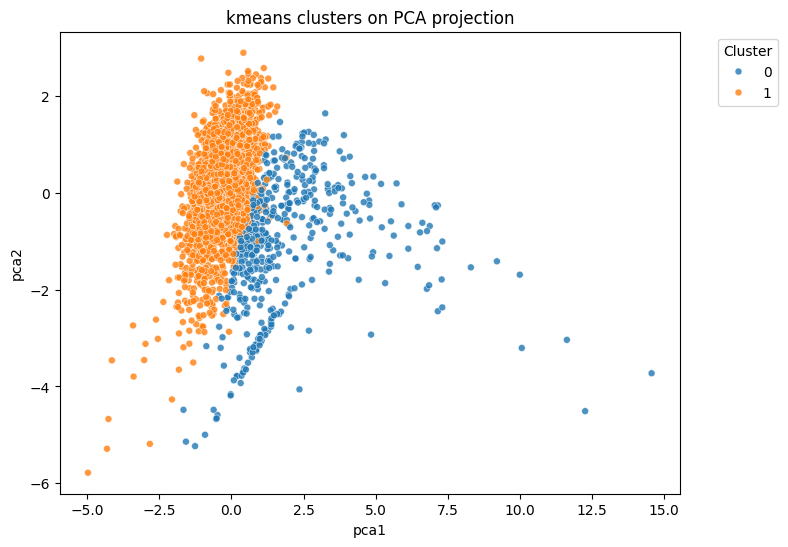

In [56]:
plot_pca("kmeans")

#### UMAP

In [57]:
!pip install umap-learn
!pip install hdbscan

In [58]:
import umap.umap_ as umap

umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42,
    n_jobs=-1
)

Z_umap = umap_model.fit_transform(X_scaled)

df["umap1"] = Z_umap[:,0]
df["umap2"] = Z_umap[:,1]

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [59]:
def plot_umap(cluster_name):
  sns.scatterplot(
    data=df,
    x="umap1", y="umap2",
    hue=f"cluster_{cluster_name}",
    s=15, alpha=0.8, palette="tab10"
  )
  plt.title(f"{cluster_name} кластеры на UMAP проекции")
  plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
  plt.show()


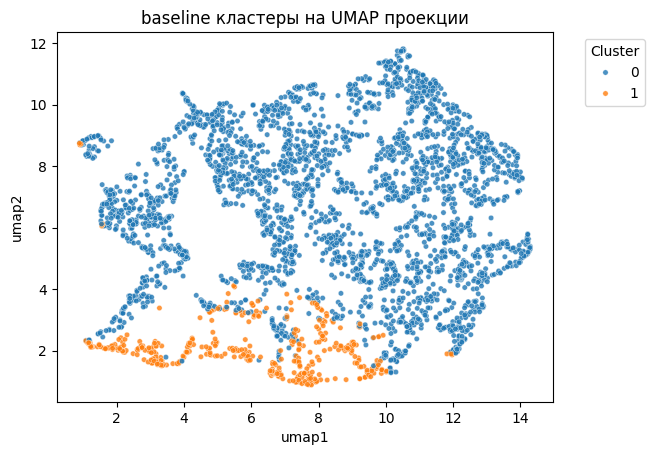

In [60]:
plot_umap("baseline")

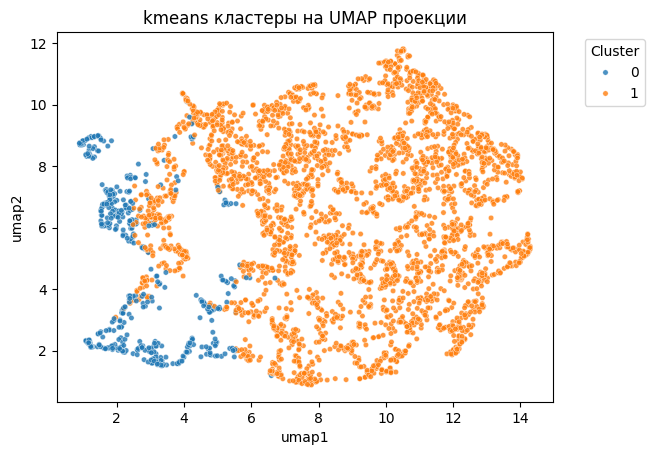

In [61]:
plot_umap("kmeans")

Для сравнения посмотрим также мягкую кластеризацию с помощью GMM


GMM


In [62]:
from sklearn.mixture import GaussianMixture

covariance_type = "full"
rc = 42
reg_covar=1e-4

Выбор числа компонент с помощью AIC и BIC

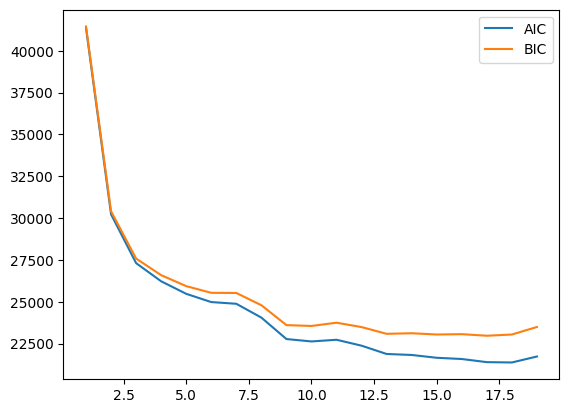

In [63]:
from sklearn.mixture import GaussianMixture

aic = []
bic = []
ks = range(1, 20)

for k in ks:
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_scaled)
    aic.append(gmm.aic(X_scaled))
    bic.append(gmm.bic(X_scaled))

plt.plot(ks, aic, label="AIC")
plt.plot(ks, bic, label="BIC")
plt.legend()
plt.show()

Нет минимума => не подходит

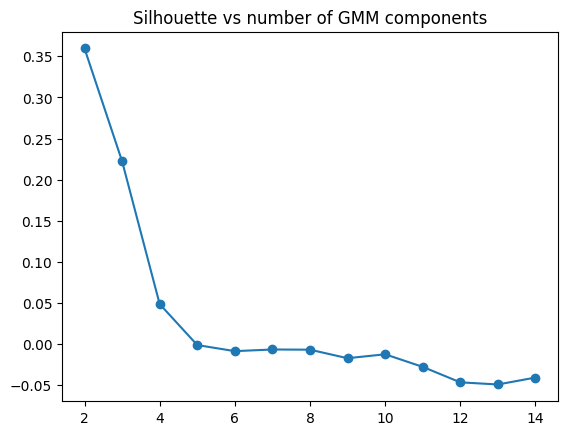

In [64]:
from sklearn.metrics import silhouette_score

sil_scores = []
ks = range(2, 15)

for k in ks:
    gmm = GaussianMixture(n_components=k).fit(X_scaled)
    labels = gmm.predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

plt.plot(ks, sil_scores, marker="o")
plt.title("Silhouette vs number of GMM components")
plt.show()


In [65]:
k = 2
gmm = GaussianMixture(n_components=k, covariance_type=covariance_type, random_state=rc, reg_covar=reg_covar)
gmm.fit(X_scaled)
df["cluster_gmm"] = gmm.predict(X_scaled)


In [66]:
# Как выглядит средний представитель каждого кластера

gmm_profile = df.groupby("cluster_gmm")[features].mean().T
gmm_profile


cluster_gmm,0,1
subscribers,1124695.21831,268893.8693
num_posts,2406.825704,13653.641618
er_general_percent,10.321444,13.91325
reactions_per_view,0.195291,0.012072


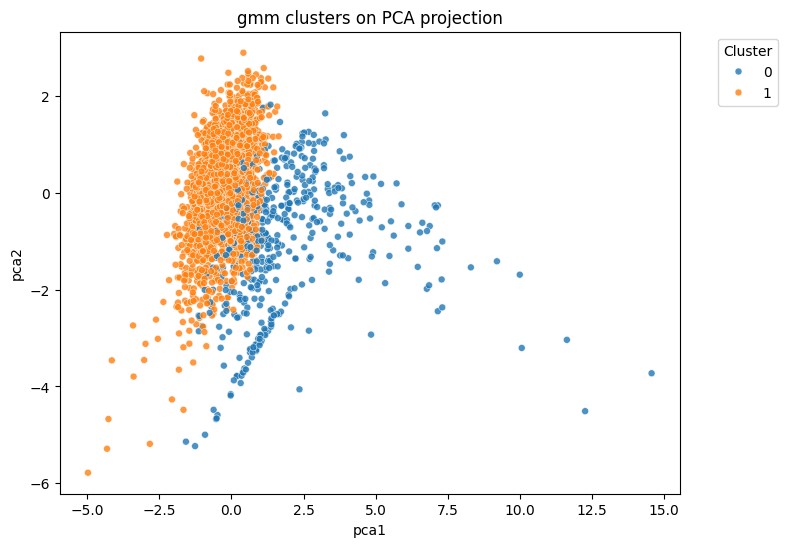

In [67]:
plot_pca("gmm")

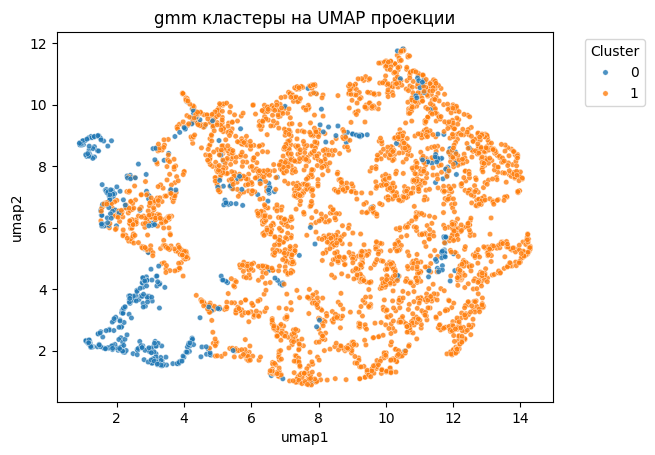

In [68]:
plot_umap("gmm")


#### Интерпретация

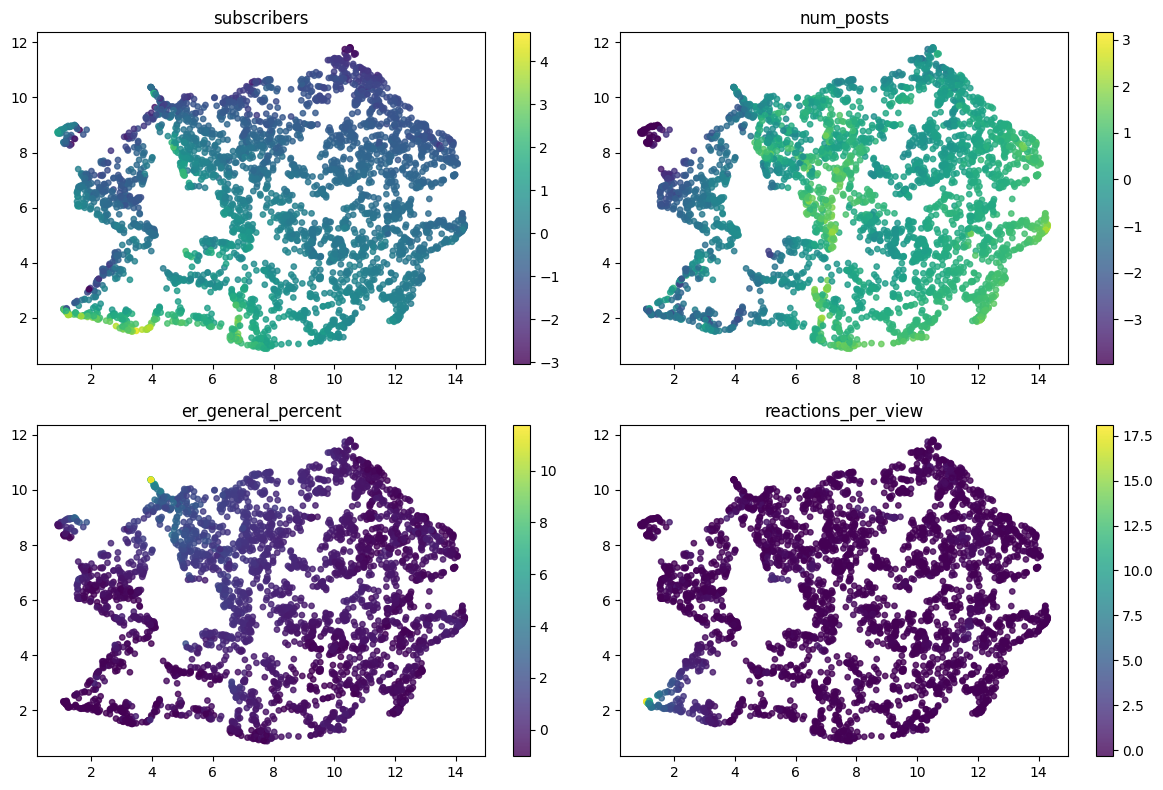

In [69]:
n = len(features)
rows = (n + 1) // 2

fig, axes = plt.subplots(rows, 2, figsize=(12, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, features):
    points = ax.scatter(
        df["umap1"],
        df["umap2"],
        c=X_scaled_df[col],
        cmap="viridis",
        s=15,
        alpha=0.8
    )
    ax.set_title(col)
    fig.colorbar(points, ax=ax)

plt.tight_layout()
plt.show()


Сопоставим полученные кластеры с имеющимися категориями каналов



In [70]:
df_merged = df.merge(df_cats, on='key', how='left')

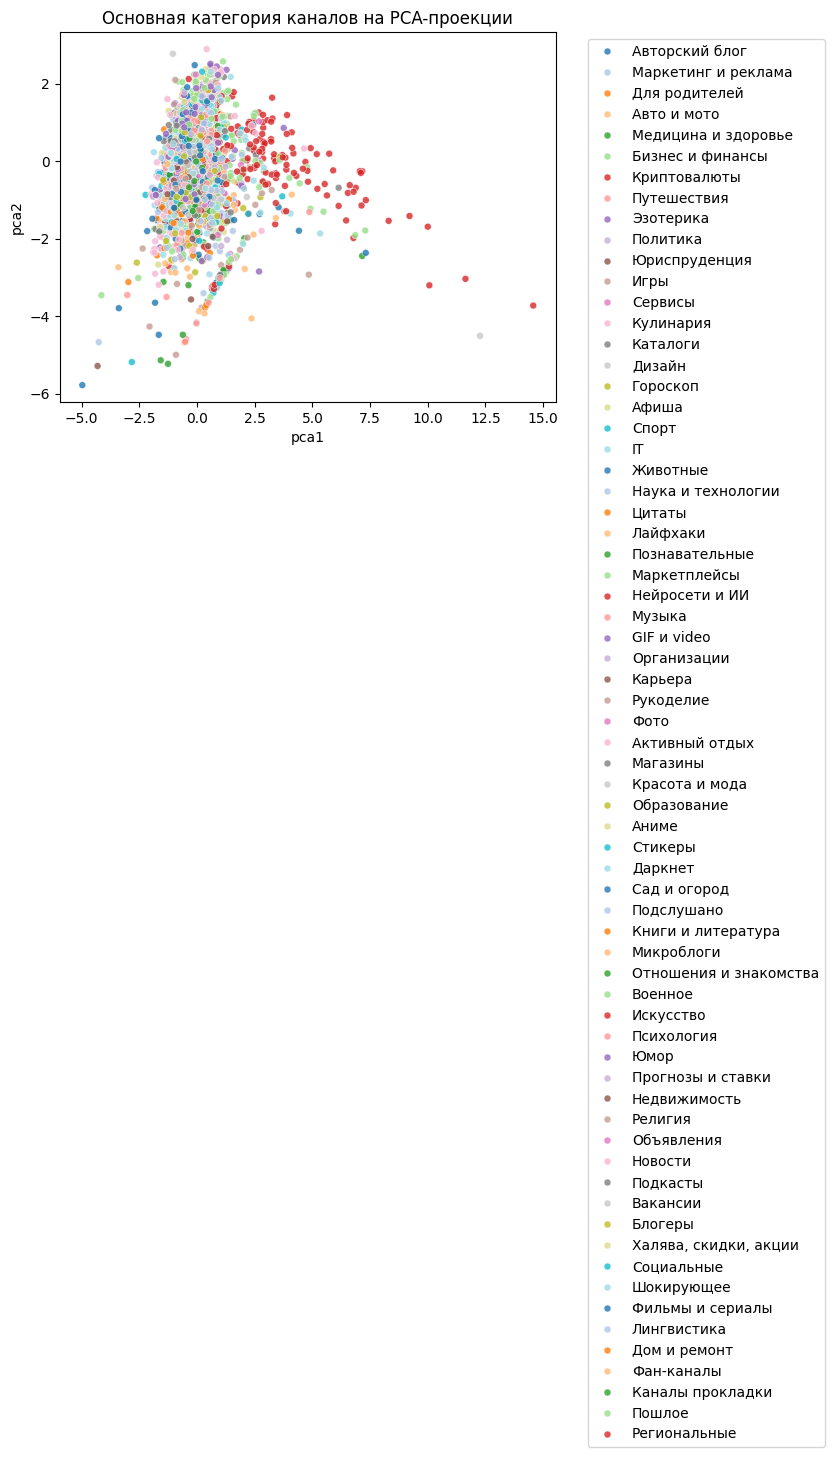

In [71]:
# Для каждого канала выберем первую категорию (если их несколько)
df_merged["main_category"] = df_merged.groupby("key")["category"].transform(lambda x: x.iloc[0])

sns.scatterplot(
    data=df_merged.drop_duplicates("key"),
    x="pca1", y="pca2",
    hue="category",
    palette="tab20",
    s=25, alpha=0.8
)
plt.title("Основная категория каналов на PCA-проекции")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()


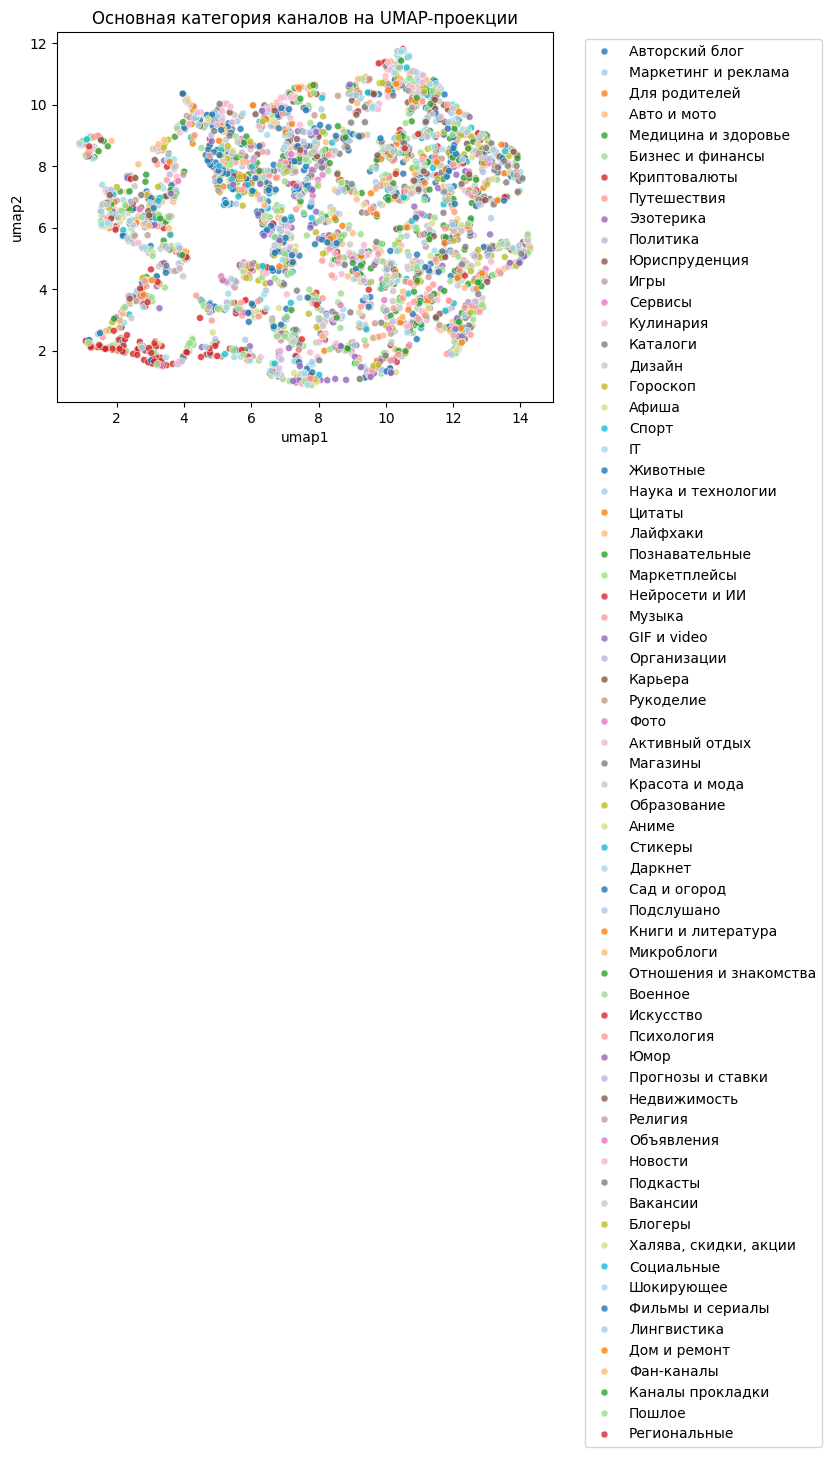

In [72]:
sns.scatterplot(
    data=df_merged.drop_duplicates("key"),
    x="umap1", y="umap2",
    hue="category",
    s=25, alpha=0.8, palette="tab20"
)
plt.title("Основная категория каналов на UMAP-проекции")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

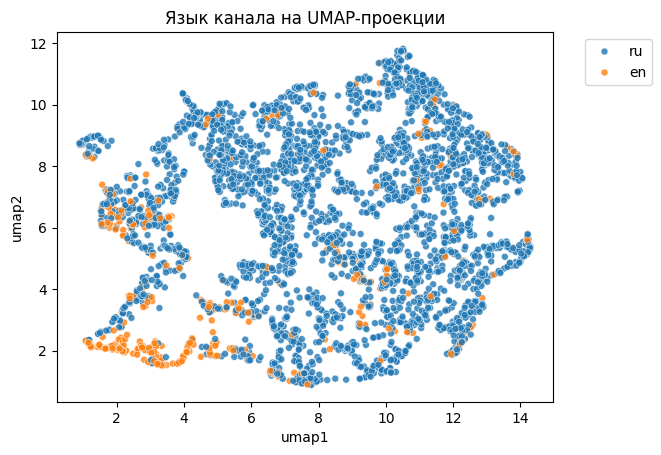

In [73]:
sns.scatterplot(
    data=df_merged.drop_duplicates("key"),
    x="umap1", y="umap2",
    hue="language",
    s=25, alpha=0.8, palette="tab10"
)
plt.title("Язык канала на UMAP-проекции")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

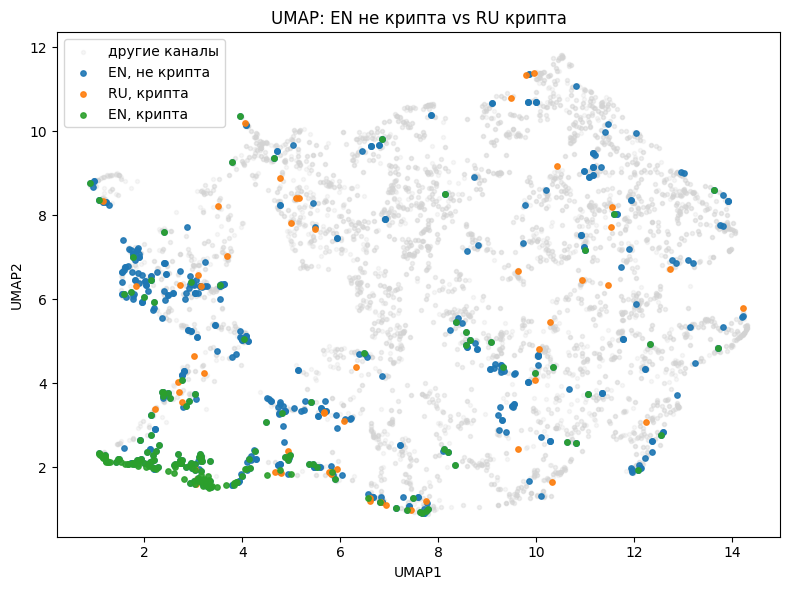

In [74]:
mask_en_not_crypto = (df_merged["lang_ru"] == 0) & (df_merged["category"] != "Криптовалюты")
mask_ru_crypto = (df_merged["lang_ru"] == 1) & (df_merged["category"] == "Криптовалюты")
mask_en_crypto = (df_merged["lang_ru"] == 0) & (df_merged["category"] == "Криптовалюты")


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    df_merged["umap1"], df_merged["umap2"],
    s=8, alpha=0.2, color="lightgray", label="другие каналы"
)

plt.scatter(
    df_merged.loc[mask_en_not_crypto, "umap1"],
    df_merged.loc[mask_en_not_crypto, "umap2"],
    s=15, alpha=0.9, label="EN, не крипта"
)

plt.scatter(
    df_merged.loc[mask_ru_crypto, "umap1"],
    df_merged.loc[mask_ru_crypto, "umap2"],
    s=15, alpha=0.9, label="RU, крипта"
)

plt.scatter(
    df_merged.loc[mask_en_crypto, "umap1"],
    df_merged.loc[mask_en_crypto, "umap2"],
    s=15, alpha=0.9, label="EN, крипта"
)


plt.legend()
plt.title("UMAP: EN не крипта vs RU крипта")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.tight_layout()
plt.show()


In [75]:
en_crypto_profile = df_merged.loc[mask_en_crypto][features].mean().T
en_crypto_profile

,0
subscribers,2537022.457447
num_posts,3170.37766
er_general_percent,3.218511
reactions_per_view,0.313395


По графикам видно, что англоязычные каналы о криптовалютах очень похожи: много подписчиков, мало постов, низкие просмотры, высокие реакции (kmeans и gmm почти угадывают этот кластер). Вероятное объяснение: использование ботов для имитации активности. Остальные категории выглядят распределенными равномерно

## Реализация k-means

Гиперпараметры:
- K - число кластеров
- max_iter - максимум итераций
- tol - критерий остановки
- random_state - состояние рандома (для воспроизоводимости)

In [76]:
def kmeans(X, K=3, max_iter=100, tol=1e-4, random_state=None):
    rng = np.random.default_rng(random_state)
    n = X.shape[0]

    # Инициализация центров случайным выбором точек
    centers = X[rng.choice(n, K, replace=False)]

    for _ in range(max_iter):
        # Шаг 1: присвоение кластеров
        # Вычисляем матрицу расстояний (строка = точка, столбец = центр) и присваиваем точки к ближайшему центру
        dists = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2)
        labels = dists.argmin(axis=1)

        # Шаг 2: пересчёт центров
        new_centers = np.array([X[labels == k].mean(axis=0) for k in range(K)])

        # Проверка сходимости (алгоритм останавливается, если центры сместились меньше, чем на tol)
        shift = np.linalg.norm(new_centers - centers)
        if shift < tol:
            centers = new_centers
            break

        centers = new_centers

    return labels, centers


In [77]:
 !pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 16.1 MB/s eta 0:00:00


In [78]:
# перебор параметров с помощью optuna: максимизируем silhouette_score
import optuna

def objective(trial):
    K = trial.suggest_int("K", 2, 10)
    max_iter = trial.suggest_int("max_iter", 50, 300)
    tol = trial.suggest_float("tol", 1e-5, 1e-2, log=True)
    random_state = trial.suggest_int("random_state", 0, 1000)

    labels, centers = kmeans(
        X_scaled,
        K=K,
        max_iter=max_iter,
        tol=tol,
        random_state=random_state
    )

    score = silhouette_score(X_scaled, labels)
    return score

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)


[I 2026-07-08 15:08:50,899] A new study created in memory with name: no-name-fea1b13c-33a5-4f80-9ee8-556c78489940
[I 2026-07-08 15:08:51,352] Trial 0 finished with value: 0.24102786447046523 and parameters: {'K': 9, 'max_iter': 274, 'tol': 0.0005852792013756983, 'random_state': 112}. Best is trial 0 with value: 0.24102786447046523.
[I 2026-07-08 15:08:51,819] Trial 1 finished with value: 0.2464188818945473 and parameters: {'K': 8, 'max_iter': 265, 'tol': 0.002014506652561217, 'random_state': 17}. Best is trial 1 with value: 0.2464188818945473.
[I 2026-07-08 15:08:52,234] Trial 2 finished with value: 0.2627262965246482 and parameters: {'K': 7, 'max_iter': 292, 'tol': 4.7770658659125855e-05, 'random_state': 450}. Best is trial 2 with value: 0.2627262965246482.
[I 2026-07-08 15:08:52,568] Trial 3 finished with value: 0.32380188757631867 and parameters: {'K': 3, 'max_iter': 149, 'tol': 4.221483254299684e-05, 'random_state': 858}. Best is trial 3 with value: 0.32380188757631867.
[I 2026-07-

In [79]:
def plot_umap_with_centers(cluster_name, centers):
  centers_emb = umap_model.transform(centers)

  sns.scatterplot(
    data=df,
    x="umap1", y="umap2",
    hue=f"cluster_{cluster_name}",
    s=15, alpha=0.8, palette="tab10"
  )
  plt.scatter(centers_emb[:, 0], centers_emb[:, 1], c=np.arange(len(centers)), s=100, marker="X")

  plt.title(f"{cluster_name} кластеры на UMAP проекции")
  plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
  plt.show()


In [80]:
best_params = study.best_params
best_value = study.best_value

labels, centers = kmeans(
    X_scaled,
    K=best_params["K"],
    max_iter=best_params["max_iter"],
    tol=best_params["tol"],
    random_state=best_params["random_state"]
)


df["cluster_kmeans_impl"] = labels


In [81]:
best_params

{'K': 2, 'max_iter': 113, 'tol': 1.092403778339317e-05, 'random_state': 994}

In [82]:
best_value

0.6519315989479069

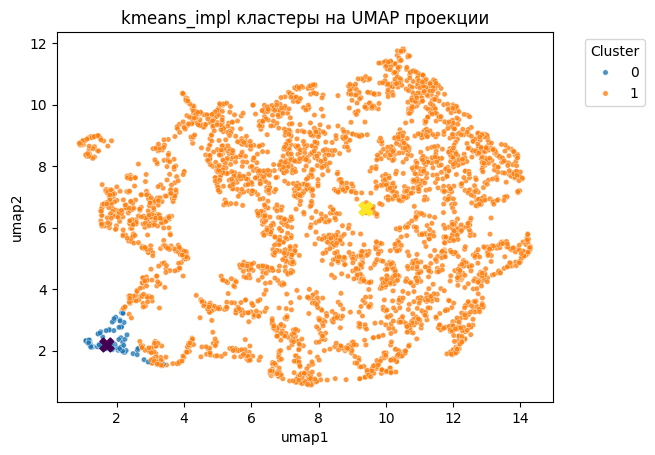

In [83]:
plot_umap_with_centers("kmeans_impl", centers)